# Does a contents page help a trained retriever find the right document?

STAIR-inspired local adaptation on one fixed SearchTome finance corpus, using FLAN-T5-small and a verified hierarchy of document-title anchors. This changes the backbone and scope of the paper's Mistral/LoRA benchmark.

The first build stopped because at least nine released documents contain multiple source sections. The user approved retaining all released documents and treating their titles as source-heading anchors. The tree describes those anchors, not an exact partition of returned content. The original failure, source excerpts, numbering crosswalk and reasoning remain in the run evidence and `docs/stair-section-boundary-decision.md`.

Correctness means agreement with the supplied released-document label. It does not establish exact source-leaf retrieval or downstream answer quality.

# Setup

Use native Python 3.12 with `requirements-stair.lock.txt`. Select that environment's notebook kernel. The implementation is inline; no repository helper imports are required. Data, cached base weights and run evidence stay external.

`report` is the default and requires complete saved v4 evidence. It recomputes metrics offline without loading weights, fitting or inference. `live` explicitly runs the gated training/dev/test study on cached inputs. `prepare` is for explicit source preparation. Missing report evidence raises rather than starting a model. Set `STAIR_ROOT` to the directory containing data/runs, or keep them beside the notebook.

The target is M4 Max/MPS float32, with a bounded pilot. Effective training batch remains eight. Positive results are not required.

In [2]:
"""Setup cell; copied inline into the standalone notebook by the authoring script."""
# Standard library
from collections import Counter, defaultdict
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import re
import random
import shutil
import subprocess
import textwrap
import time
import unicodedata
import threading
from contextlib import contextmanager

# Keep Matplotlib's cache writable in isolated notebook execution.
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ.get("STAIR_ROOT", ".")).resolve() / "data/stair/mpl-cache"))
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "0"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_OFFLINE"] = "0" if os.environ.get("STAIR_MODE") == "prepare" else "1"

# Third-party packages: requests/preparation, analysis, graphics and display.
import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn.functional as torch_F
from rank_bm25 import BM25Okapi
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, GenerationConfig, LogitsProcessor, LogitsProcessorList
from huggingface_hub import snapshot_download
from IPython.display import Image, Markdown, display


class CFG:
    MODE = os.environ.get("STAIR_MODE", "report")
    root = Path(os.environ.get("STAIR_ROOT", ".")).resolve()
    data_folder = root / "data/stair"
    run_folder = root / "runs/stair"
    graph_folder = root / "graphs/stair"
    dataset = "meghanadh/SearchTome"
    dataset_revision = "48d3b3545950b3857dc3657fb22e4b79b8ed8df5"
    dataset_files = ("finance/corpus.jsonl", "finance/train.jsonl", "finance/dev.jsonl",
                     "finance/test.jsonl", "README.md", "LICENSE", "stats.json")
    source_pdf_url = "https://open.umn.edu/opentextbooks/formats/1101"
    source_pdf_sha256 = "ddc74629d85972a05bc362c0e3f3a23e678b4869c8b97a512aba00bf1a220174"
    source_toc_pdf_pages = (5, 6, 7, 8, 9)  # One-based physical PDF pages.
    source_body_first_pdf_page = 11
    seed = 42
    encoder_cap = 4096
    decoder_cap = 96
    preferred_profile = {"train": 256, "dev": 48, "test": 120, "epochs": 4}
    fallback_profile = {"train": 128, "dev": 32, "test": 60, "epochs": 3}
    measured_budget_minutes = 180
    pilot_budget_minutes = 30
    model = "google/flan-t5-small"
    model_revision = "0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab"
    preferred_backend = "mps"
    model_dtype = "float32"
    target_contract = "released_document_anchor_v4"
    effective_batch = 8
    batch_accumulation_candidates = ((4, 2), (2, 4), (1, 8))
    inference_batch_candidates = (1, 2, 4)
    model_folder = data_folder / "model"
    learning_rate = 1e-4
    bootstrap_seed = 42001
    order_seed = 42002
    bootstrap_replicates = 10000
    rss_limit_gib = 48
    available_floor_gib = 32
    swap_growth_limit_gib = 1
    resume_run_id = os.environ.get("STAIR_RUN_ID")
    img_dim1, img_dim2 = 9.5, 6.5
    example_figure_height = 8.0
    export_dpi = 200
    asset_suffix = "0311"


if CFG.MODE not in {"prepare", "report", "live"}:
    raise ValueError("STAIR_MODE must be prepare, report or live")
plt.style.use("seaborn-v0_8")
plt.rcParams.update({"figure.figsize": (CFG.img_dim1, CFG.img_dim2), "font.size": 11})
np.random.seed(CFG.seed)
print(f"Mode: {CFG.MODE}; inputs: {CFG.data_folder}")

Matplotlib is building the font cache; this may take a moment.


Mode: report; inputs: /private/tmp/stair-replay-ahup_tff/data/stair


Setup centralizes source identity, modes, paths, model settings, seeds and budgets. Unsupported-operation MPS fallback is disabled before torch imports. Report mode never trains because a cache is missing.

# Utils

## Evidence and explicit preparation

In [3]:
def canonical(text):
    """The approved title normalization: NFC and whitespace only."""
    return " ".join(unicodedata.normalize("NFC", text).split())


def source_match_key(text):
    """Case-insensitive source-heading audit only, never a prediction evaluator."""
    return canonical(text).casefold()


def digest_bytes(payload):
    return hashlib.sha256(payload).hexdigest()


def json_read(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def json_write(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".partial")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n",
                         encoding="utf-8")
    temporary.replace(path)


def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]


def package_inventory():
    result = {"python": platform.python_version(), "architecture": platform.machine(),
              "platform": platform.platform()}
    for name in ("numpy", "pandas", "matplotlib", "httpx", "nbformat", "nbclient", "torch", "transformers"):
        try:
            result[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            result[name] = None
    return result


def prepare_sources():
    """Explicit preparation only; model downloads/inference are never launched here."""
    if CFG.MODE != "prepare":
        raise RuntimeError("Network preparation requires MODE='prepare'")
    started = time.monotonic()
    raw = CFG.data_folder / "raw"
    source = CFG.data_folder / "source_book"
    source.mkdir(parents=True, exist_ok=True)
    files = []
    with httpx.Client(timeout=120, follow_redirects=True) as client:
        for name in CFG.dataset_files:
            url = f"https://huggingface.co/datasets/{CFG.dataset}/resolve/{CFG.dataset_revision}/{name}"
            response = client.get(url)
            response.raise_for_status()
            target = raw / name
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(response.content)
            files.append({"path": name, "url": url, "sha256": digest_bytes(response.content),
                          "bytes": len(response.content)})
        response = client.get(CFG.source_pdf_url)
        response.raise_for_status()
        if digest_bytes(response.content) != CFG.source_pdf_sha256:
            raise ValueError("The source PDF differs from the reviewed snapshot; revise provenance before continuing")
        (source / "principles-of-financial-accounting.pdf").write_bytes(response.content)
        json_write(source / "manifest.json", {"url": CFG.source_pdf_url, "resolved_url": str(response.url),
                   "sha256": CFG.source_pdf_sha256, "bytes": len(response.content),
                   "attribution": "Christine Jonick; University System of Georgia; University of North Georgia Press, 2017",
                   "license": "CC BY-SA 4.0; see copyright page for third-party exceptions"})
    if not shutil.which("pdftotext"):
        raise RuntimeError("Preparation needs Poppler's pdftotext on PATH; report mode uses the supplied cached extraction")
    subprocess.run(["pdftotext", "-layout", str(source / "principles-of-financial-accounting.pdf"),
                    str(source / "book.txt")], check=True, capture_output=True)
    extractor = subprocess.run(["pdftotext", "-v"], capture_output=True, text=True)
    json_write(CFG.data_folder / "source_manifest.json", {"dataset": CFG.dataset,
               "revision": CFG.dataset_revision, "files": files,
               "preparation_seconds": time.monotonic() - started})
    json_write(source / "extraction_manifest.json", {"pdf_sha256": CFG.source_pdf_sha256,
               "text_sha256": digest_bytes((source / "book.txt").read_bytes()),
               "extractor": (extractor.stdout + extractor.stderr).splitlines()[0],
               "command": "pdftotext -layout principles-of-financial-accounting.pdf book.txt"})


def validate_inputs():
    manifest_path = CFG.data_folder / "source_manifest.json"
    if not manifest_path.exists():
        raise FileNotFoundError("Cached STAIR evidence is missing. Supply data/stair or explicitly run MODE='prepare'.")
    manifest = json_read(manifest_path)
    if manifest["revision"] != CFG.dataset_revision or manifest["dataset"] != CFG.dataset:
        raise ValueError("Dataset identity/revision differs from the approved snapshot")
    if set(row["path"] for row in manifest["files"]) != set(CFG.dataset_files):
        raise ValueError("Unexpected source-file membership")
    for row in manifest["files"]:
        path = CFG.data_folder / "raw" / row["path"]
        expected_url = f"https://huggingface.co/datasets/{CFG.dataset}/resolve/{CFG.dataset_revision}/{row['path']}"
        if row["url"] != expected_url or digest_bytes(path.read_bytes()) != row["sha256"]:
            raise ValueError(f"Source identity/hash mismatch: {row['path']}")
    source = CFG.data_folder / "source_book"
    if digest_bytes((source / "principles-of-financial-accounting.pdf").read_bytes()) != CFG.source_pdf_sha256:
        raise ValueError("Source PDF hash differs from the reviewed snapshot")
    extraction = json_read(source / "extraction_manifest.json")
    if extraction["pdf_sha256"] != CFG.source_pdf_sha256 or digest_bytes((source / "book.txt").read_bytes()) != extraction["text_sha256"]:
        raise ValueError("Cached source-text extraction failed provenance checks")
    return manifest


def prepare_model_cache():
    if CFG.MODE != "prepare":
        raise RuntimeError("Model downloads require explicit prepare mode")
    started = time.monotonic()
    snapshot_download(CFG.model, revision=CFG.model_revision, local_dir=CFG.model_folder,
                      allow_patterns=["*.json", "spiece.model", "model.safetensors", "README.md"],
                      token=False, max_workers=2)
    files = [{"path": path.name, "sha256": digest_bytes(path.read_bytes()), "bytes": path.stat().st_size}
             for path in sorted(CFG.model_folder.iterdir()) if path.is_file()]
    json_write(CFG.data_folder / "model_manifest.json", {"model": CFG.model, "revision": CFG.model_revision,
               "files": files, "preparation_seconds": time.monotonic() - started, "license": "Apache-2.0"})


def validate_model_cache():
    manifest = json_read(CFG.data_folder / "model_manifest.json")
    if manifest["model"] != CFG.model or manifest["revision"] != CFG.model_revision:
        raise ValueError("Model identity/revision differs from the pinned checkpoint")
    for row in manifest["files"]:
        if digest_bytes((CFG.model_folder / row["path"]).read_bytes()) != row["sha256"]:
            raise ValueError("Model cache checksum failed: " + row["path"])
    return manifest

These helpers validate pinned inputs and save evidence atomically. Preparation is explicit; corpus bytes stay outside the notebook.

## Source anchors and frozen membership

In [4]:
def source_toc(book_text):
    """Parse numbered source entries, including wrapped titles and duplicate codes.

    Identity includes source order. The printed book repeats number 6.4; treating
    that code alone as an ID would merge two different sections.
    """
    pages = book_text.split("\f")
    result = []
    for pdf_page in CFG.source_toc_pdf_pages:
        current = []
        for line in pages[pdf_page - 1].splitlines():
            line = line.strip()
            if re.match(r"^\d+(?:\.\d+)+\s", line):
                if current:
                    raise ValueError(f"Unparsed source ToC entry on PDF page {pdf_page}: {current}")
                current = [line]
            elif current:
                current.append(line)
            joined = " ".join(current)
            match = re.match(r"^(\d+(?:\.\d+)+)\s+(.*?)\s+\.(?:\s*\.)*\s*(\d+)$", joined)
            if match:
                code, title, printed_page = match.groups()
                result.append({"source_id": f"toc-{len(result):03d}", "code": code,
                               "title": canonical(title), "printed_page": int(printed_page),
                               "toc_pdf_page": pdf_page, "source_order": len(result)})
                current = []
        if current:
            raise ValueError(f"Incomplete source ToC entry on PDF page {pdf_page}: {current}")
    if not result:
        raise ValueError("Source ToC parser returned no entries")
    for row in result:
        row["leaf"] = not any(other["code"].startswith(row["code"] + ".") for other in result)
    return result


def heading_matches(body, leaves):
    """Positive evidence of known source-leaf headings inside one released document.

    Both the exact printed code and the complete source heading must match.
    Wrapped headings are allowed. Decimal amounts cannot qualify by code alone.
    A single detected heading does not certify clean section boundaries.
    """
    found = []
    for leaf in leaves:
        words = canonical(leaf["title"]).split()
        pattern = r"^\s*" + re.escape(leaf["code"]) + r"\s+" + r"\s+".join(map(re.escape, words))
        pattern += r"(?=\s|$)"
        match = re.search(pattern, body, re.I | re.M)
        if match:
            start = match.start()
            found.append({"source_id": leaf["source_id"], "source_code": leaf["code"],
                          "source_title": leaf["title"], "printed_page": leaf["printed_page"],
                          "toc_pdf_page": leaf["toc_pdf_page"], "content_offset": start,
                          "content_line": body[:start].count("\n") + 1,
                          "evidence_excerpt": body[start:start + 500].strip()})
    return sorted(found, key=lambda row: row["content_offset"])


def audit_release(contract=None):
    contract = contract or CFG.target_contract
    if contract not in {"source_leaf_v3", "released_document_anchor_v4"}:
        raise ValueError("Unrecognized retrieval-unit contract")
    validate_inputs()
    raw = CFG.data_folder / "raw/finance"
    corpus = read_jsonl(raw / "corpus.jsonl")
    book = (CFG.data_folder / "source_book/book.txt").read_text(encoding="utf-8")
    toc = source_toc(book)
    leaves = [row for row in toc if row["leaf"]]
    titles = [canonical(row["title"]) for row in corpus]
    title_set = set(titles)
    title_collisions = [title for title, count in Counter(titles).items() if count > 1]
    empty_content = [i for i, row in enumerate(corpus) if not row["content"].strip()]
    content_groups = defaultdict(list)
    target_crosswalk, documents, problems = [], [], []
    for index, row in enumerate(corpus):
        title = canonical(row["title"])
        content_groups[digest_bytes(row["content"].encode())].append(index)
        match = re.fullmatch(r"(\d+(?:\.\d+)+)\s+(.+)", title)
        candidates = []
        if match:
            code, semantic_title = match.groups()
            candidates = [leaf for leaf in leaves if source_match_key(leaf["title"]) == source_match_key(semantic_title)
                          and leaf["code"] == code]
            if not candidates:
                # Source-numbering discrepancy is recorded, never used to relabel targets.
                candidates = [leaf for leaf in leaves if source_match_key(leaf["title"]) == source_match_key(semantic_title)
                              and leaf["code"].split(".")[0] == code.split(".")[0]]
        if len(candidates) != 1:
            problems.append({"section_id": f"finance:{index:03d}", "title": title,
                             "reason": "source_leaf_mapping_not_unique", "matches": len(candidates)})
        mapped = candidates[0] if len(candidates) == 1 else None
        if mapped:
            target_crosswalk.append({"section_id": f"finance:{index:03d}", "release_title": row["title"],
                                     "canonical_title": title, "source_id": mapped["source_id"],
                                     "source_title": mapped["code"] + " " + mapped["title"],
                                     "source_printed_page": mapped["printed_page"],
                                     "source_toc_pdf_page": mapped["toc_pdf_page"],
                                     "numbering_differs": match.group(1) != mapped["code"]})
        headings = heading_matches(row["content"], leaves)
        documents.append({"section_id": f"finance:{index:03d}", "release_title": row["title"],
                          "body_sha256": digest_bytes(row["content"].encode()),
                          "mapped_source_id": mapped["source_id"] if mapped else None,
                          "source_leaf_headings": headings,
                          "confirmed_multi_leaf": len(headings) > 1,
                          "target_heading_detected": mapped is not None and any(h["source_id"] == mapped["source_id"] for h in headings)})
    duplicates = [group for group in content_groups.values() if len(group) > 1]
    query_counts, missing_gold, query_id_collisions = {}, [], []
    for split in ("train", "dev", "test"):
        rows = read_jsonl(raw / f"{split}.jsonl")
        query_counts[split] = len(rows)
        ids = [f"finance:{split}:{row['query_id']}" for row in rows]
        query_id_collisions.extend(key for key, n in Counter(ids).items() if n > 1)
        for row in rows:
            if canonical(row["gold_doc_title"]) not in title_set:
                missing_gold.append({"split": split, "query_id": row["query_id"], "title": row["gold_doc_title"]})
    multi_leaf = [row for row in documents if row["confirmed_multi_leaf"]]
    unseen_heading = [row["release_title"] for row in documents if not row["target_heading_detected"]]
    target_sources = {row["source_id"] for row in target_crosswalk}
    observed_sources = {heading["source_id"] for row in documents for heading in row["source_leaf_headings"]}
    source_missing_as_targets = [row for row in leaves if row["source_id"] not in target_sources]
    duplicate_source_codes = [code for code, n in Counter(row["code"] for row in toc).items() if n > 1]
    fatal = []
    if title_collisions or empty_content or duplicates or missing_gold or query_id_collisions:
        fatal.append("release_structural_integrity_failed")
    if problems or unseen_heading:
        fatal.append("source_leaf_mapping_or_heading_verification_failed")
    if multi_leaf and contract == "source_leaf_v3":
        fatal.append("released_documents_contain_multiple_source_leaves")
    if len(target_sources) != len(target_crosswalk):
        fatal.append("release_to_source_mapping_not_injective")
    return {"status": "stopped_at_data_gate" if fatal else "data_gate_passed_with_boundary_warnings",
            "target_contract": contract,
            "historical_source_leaf_gate": {"status": "failed" if multi_leaf else "passed",
                                            "confirmed_multi_leaf_documents": len(multi_leaf)},
            "quality_warnings": ["released_documents_contain_multiple_source_leaves"] if multi_leaf else [],
            "fatal_reasons": fatal, "dataset_revision": CFG.dataset_revision,
            "source_pdf_sha256": CFG.source_pdf_sha256,
            "corpus_documents": len(corpus), "query_counts": query_counts,
            "source_toc_entries": len(toc), "source_leaf_count": len(leaves),
            "source_duplicate_number_codes": duplicate_source_codes,
            "confirmed_multi_leaf_documents": len(multi_leaf),
            "numbering_discrepancies": sum(row["numbering_differs"] for row in target_crosswalk),
            "source_leaves_not_direct_targets": source_missing_as_targets,
            "non_target_source_headings_observed_in_content": sorted(observed_sources - target_sources),
            "title_collisions": title_collisions, "empty_content": empty_content,
            "duplicate_content_groups": duplicates, "missing_gold_titles": missing_gold,
            "query_id_collisions": query_id_collisions, "mapping_problems": problems,
            "undetected_target_headings": unseen_heading, "crosswalk": target_crosswalk,
            "source_toc": toc, "document_audit": documents,
            "model_downloaded": False, "training_started": False, "test_predictions": 0,
            "execution_flags_scope": "Operations inside this source-audit function only; complete run status/model provenance are separate",
            "detection_limit": "Multiple exact source-leaf headings establish merged content. A single heading does not certify clean boundaries; unmarked spillover may remain."}


def build_anchor_hierarchy(audit):
    if audit["fatal_reasons"]:
        raise ValueError(f"Anchor admission failed: {audit['fatal_reasons']}")
    toc = audit["source_toc"]
    source_by_id = {row["source_id"]: row for row in toc}
    pages = (CFG.data_folder / "source_book/book.txt").read_text().split("\f")
    chapters = {}
    for page_num in CFG.source_toc_pdf_pages:
        current = []
        for line in pages[page_num - 1].splitlines():
            line = line.strip()
            if re.match(r"^Chapter \d+:", line):
                current = [line]
            elif current:
                current.append(line)
            match = re.match(r"^Chapter (\d+):\s+(.*?)\s+(\d+)$", " ".join(current))
            if match:
                number, title, printed_page = match.groups()
                chapters[number] = {"node_id": "chapter-" + number,
                                    "label": "Chapter " + number + ": " + canonical(title),
                                    "toc_pdf_page": page_num, "source_printed_page": int(printed_page)}
                current = []
    nodes, edges, lines = {}, [], []
    target_ids = []
    for anchor in audit["crosswalk"]:
        source = source_by_id[anchor["source_id"]]
        parts = source["code"].split(".")
        chapter = chapters.get(parts[0])
        if not chapter:
            raise ValueError("Missing verified source chapter: " + parts[0])
        parent_id = chapter["node_id"]
        if parent_id not in nodes:
            nodes[parent_id] = {**chapter, "parent_id": None, "target": False}
            lines.append(chapter["label"])
        for depth in range(2, len(parts)):
            prefix = ".".join(parts[:depth])
            ancestors = [row for row in toc if row["code"] == prefix]
            if len(ancestors) != 1 or ancestors[0]["leaf"]:
                raise ValueError("Ambiguous/missing source ancestor: " + prefix)
            ancestor = ancestors[0]
            ancestor_id = ancestor["source_id"]
            if ancestor_id not in nodes:
                label = prefix + " " + ancestor["title"]
                nodes[ancestor_id] = {"node_id": ancestor_id, "parent_id": parent_id,
                                      "label": label, "target": False,
                                      "toc_pdf_page": ancestor["toc_pdf_page"]}
                edges.append([parent_id, ancestor_id])
                lines.append("  " * (depth - 1) + label)
            parent_id = ancestor_id
        target_id = anchor["section_id"]
        if target_id in nodes:
            raise ValueError("Duplicate target ID")
        nodes[target_id] = {"node_id": target_id, "parent_id": parent_id, "target": True,
                            "label": anchor["canonical_title"], "source_id": source["source_id"]}
        edges.append([parent_id, target_id])
        target_ids.append(target_id)
        lines.append("  " * (len(parts) - 1) + anchor["canonical_title"])
    if len(target_ids) != audit["corpus_documents"] or len(set(target_ids)) != len(target_ids):
        raise ValueError("Incomplete anchor coverage")
    for node_id, node in nodes.items():
        visited = set()
        current = node_id
        while current is not None:
            if current in visited or current not in nodes:
                raise ValueError("Cycle or disconnected source hierarchy")
            visited.add(current)
            current = nodes[current]["parent_id"]
        if node["target"] and any(parent == node_id for parent, _ in edges):
            raise ValueError("A retrieval anchor is also an ancestor")
    return {"nodes": list(nodes.values()), "edges": edges, "target_ids": target_ids,
            "hierarchical_text": "\n".join(lines),
            "flat_text": "\n".join(row["canonical_title"] for row in audit["crosswalk"]),
            "meaning": "Verified ancestor paths of released-document title anchors; not a content partition"}


def freeze_memberships(audit):
    """Apply the prospectively declared duplicate components before hash sampling."""
    raw = CFG.data_folder / "raw/finance"
    rows = []
    for priority, split in enumerate(("train", "dev", "test")):
        for item in read_jsonl(raw / f"{split}.jsonl"):
            query_id = f"finance:{split}:{item['query_id']}"
            normalized = canonical(item["query"]).casefold()
            rows.append({"query_id": query_id, "query": item["query"], "split": split,
                         "priority": priority, "gold_title": canonical(item["gold_doc_title"]),
                         "answer": item["answer"], "normalized": normalized,
                         "tokens": set(re.findall(r"\w+", normalized, re.UNICODE))})
    parent = list(range(len(rows)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i, row in enumerate(rows):
        left = row["tokens"]
        for j in range(i):
            right = rows[j]["tokens"]
            if min(len(left), len(right)) < 0.9 * max(len(left), len(right)):
                continue
            union_size = len(left | right)
            similarity = len(left & right) / union_size if union_size else 1.0
            if row["normalized"] == rows[j]["normalized"] or similarity >= 0.9:
                parent[find(i)] = find(j)
    groups = defaultdict(list)
    for i, row in enumerate(rows):
        groups[find(i)].append(row)
    eligible = defaultdict(list)
    exclusions = []
    for component in groups.values():
        first_priority = min(row["priority"] for row in component)
        retained = min((row for row in component if row["priority"] == first_priority), key=lambda r: r["query_id"])
        component_id = digest_bytes("|".join(sorted(r["query_id"] for r in component)).encode())[:16]
        for row in component:
            row["component_id"] = component_id
            row.pop("tokens")
            if row is retained:
                row["sample_hash"] = digest_bytes(f"stair-v1|{row['split']}|{row['query_id']}|{row['normalized']}".encode())
                eligible[row["split"]].append(row)
            else:
                exclusions.append({"query_id": row["query_id"], "retained_id": retained["query_id"],
                                   "component_id": component_id, "reason": "exact_or_jaccard_0.9_component; split priority then lowest qualified ID"})
    profiles = {}
    for name, sizes in (("preferred", CFG.preferred_profile), ("fallback", CFG.fallback_profile)):
        profiles[name] = {}
        for split in ("train", "dev", "test"):
            ordered = sorted(eligible[split], key=lambda row: row["sample_hash"])
            if len(ordered) < sizes[split]:
                raise ValueError(f"Insufficient duplicate-filtered {split} queries for {name}: {len(ordered)}")
            profiles[name][split] = ordered[:sizes[split]]
    return {"profiles": profiles, "exclusions": exclusions,
            "eligible_counts": {split: len(items) for split, items in eligible.items()},
            "paragraph_independence": "unverified: the release has no source paragraph IDs",
            "rule": "connected components of normalized exact matches or word-token-set Jaccard >=0.9; train/dev/test priority; lowest qualified ID"}

The historical source-leaf contract still fails on mixed-section documents. V4 retains that observation as a warning, builds verified anchor paths, and freezes duplicate-filtered memberships before outputs exist.

## Model, exact targets and decoding

In [5]:
def synchronize(device):
    if str(device) == "mps":
        torch.mps.synchronize()


def seed_model(seed, device):
    random.seed(seed)
    torch.manual_seed(seed)
    if str(device) == "mps":
        torch.mps.manual_seed(seed)


def release_model(model=None):
    del model
    gc.collect()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()


def load_base(device):
    manifest = json_read(CFG.data_folder / "model_manifest.json")
    if manifest["model"] != CFG.model:
        raise ValueError("Unexpected base model identity")
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG.model_folder, local_files_only=True,
                                                 dtype=torch.float32, attn_implementation="eager")
    model.to(device)
    if any(parameter.device.type != str(device) or parameter.dtype != torch.float32 for parameter in model.parameters()):
        raise ValueError("Model placement/dtype admission failed")
    return model


def prompt_text(fmt, query, hierarchy):
    context = "" if fmt == "D" else hierarchy["flat_text"] if fmt == "E" else hierarchy["hierarchical_text"]
    return ("Return exactly one document title from Principles of Financial Accounting.\n"
            + context + "\nQuestion: " + query + "\nTitle:")


def tokenizer_admission(corpus, hierarchy, memberships):
    tokenizer = AutoTokenizer.from_pretrained(CFG.model_folder, local_files_only=True, use_fast=True)
    original_limit = tokenizer.model_max_length
    tokenizer.model_max_length = CFG.encoder_cap  # Explicit admission cap, not a pretraining claim.
    sequences, title_by_tokens = [], {}
    for row in corpus:
        title = canonical(row["title"])
        tokens = tokenizer.encode(title, add_special_tokens=True)
        decoded = canonical(tokenizer.decode(tokens, skip_special_tokens=True, clean_up_tokenization_spaces=False))
        if tokenizer.unk_token_id in tokens or decoded != title or tuple(tokens) in title_by_tokens:
            raise ValueError(f"Unrepresentable or non-injective target: {title}")
        if tokens[-1] != tokenizer.eos_token_id or len(tokens) > CFG.decoder_cap:
            raise ValueError("Target EOS/length admission failed")
        sequences.append(tokens)
        title_by_tokens[tuple(tokens)] = title
    lengths = {}
    for fmt in ("D", "E", "F"):
        values = [len(tokenizer.encode(prompt_text(fmt, row["query"], hierarchy), truncation=False))
                  for split in memberships["profiles"]["preferred"].values() for row in split]
        if max(values) > CFG.encoder_cap:
            raise ValueError("Complete input exceeds cap; no truncation permitted")
        lengths[fmt] = {"min": min(values), "median": float(np.median(values)), "max": max(values)}
    return tokenizer, sequences, {"tokenizer_class": type(tokenizer).__name__, "original_tokenizer_limit": original_limit,
                                   "encoder_cap": CFG.encoder_cap, "input_lengths": lengths,
                                   "max_target_length": max(map(len, sequences)), "target_roundtrip": "passed",
                                   "target_injectivity": "passed"}


class TargetTrie:
    def __init__(self, sequences):
        self.root = {}
        self.eos_id = int(sequences[0][-1])
        for tokens in sequences:
            node = self.root
            for token in tokens:
                node = node.setdefault(int(token), {})

    def allowed(self, prefix):
        node = self.root
        for position, token in enumerate(prefix):
            if int(token) not in node:
                raise ValueError("Decoder prefix is outside the admitted target trie")
            node = node[int(token)]
            if int(token) == self.eos_id:
                # Transformers 4.57 retains finished beam slots while other
                # beams/queries continue. Only a verified complete title can
                # reach this no-op state; it cannot legalize an invalid title.
                if any(int(extra) not in (0, self.eos_id) for extra in prefix[position + 1:]):
                    raise ValueError("Unexpected tokens after a completed target")
                return [self.eos_id]
        return sorted(node)


class TrieMask(LogitsProcessor):
    def __init__(self, trie):
        self.trie = trie
        self.checked_normalization = False

    def __call__(self, input_ids, scores):
        if not self.checked_normalization:
            normalizers = torch.logsumexp(scores, dim=-1)
            if not torch.allclose(normalizers, torch.zeros_like(normalizers), atol=1e-4, rtol=1e-4):
                raise ValueError("Trie mask must receive full-vocabulary log probabilities")
            self.checked_normalization = True
        masked = torch.full_like(scores, -float("inf"))
        for i, sequence in enumerate(input_ids.tolist()):
            allowed = self.trie.allowed(sequence[1:])
            if not allowed:
                raise ValueError("Nonterminal hypothesis has no allowed continuation")
            masked[i, allowed] = scores[i, allowed]
        return masked


def decode_batch(model, tokenizer, trie, fmt, mode, queries, hierarchy, device, return_count=3):
    started = time.monotonic()
    prompts = [prompt_text(fmt, row["query"], hierarchy) for row in queries]
    encoded = tokenizer(prompts, return_tensors="pt", padding=True, truncation=False)
    if encoded.input_ids.shape[1] > CFG.encoder_cap:
        raise ValueError("Complete batch exceeds encoder cap")
    lengths = encoded.attention_mask.sum(dim=1).tolist()
    encoded = encoded.to(device)
    config = GenerationConfig.from_model_config(model.config)
    config.update(num_beams=4, num_return_sequences=return_count, do_sample=False,
                  max_new_tokens=CFG.decoder_cap, length_penalty=1.0, early_stopping="never",
                  renormalize_logits=False, forced_eos_token_id=None, forced_bos_token_id=None,
                  repetition_penalty=1.0, no_repeat_ngram_size=0, remove_invalid_values=False,
                  return_dict_in_generate=True, output_scores=True, use_cache=True)
    processor = LogitsProcessorList([TrieMask(trie)]) if mode == "constrained" else LogitsProcessorList()
    model.eval()
    synchronize(device)
    model_started = time.monotonic()
    with torch.inference_mode():
        output = model.generate(**encoded, generation_config=config, logits_processor=processor)
        transitions = model.compute_transition_scores(output.sequences, output.scores,
                                                      output.beam_indices, normalize_logits=False)
    synchronize(device)
    model_seconds = time.monotonic() - model_started
    ids = output.sequences.cpu().tolist()
    transitions = transitions.cpu().tolist()
    scores = output.sequences_scores.cpu().tolist()
    mapping = {canonical(row["title"]): f"finance:{i:03d}" for i, row in enumerate(hierarchy["corpus"])}
    records = []
    for i, query in enumerate(queries):
        hypotheses = []
        for rank in range(return_count):
            index = i * return_count + rank
            generated = ids[index][1:]
            complete = tokenizer.eos_token_id in generated
            length = generated.index(tokenizer.eos_token_id) + 1 if complete else len(generated)
            generated = generated[:length]
            token_scores = transitions[index][:length]
            reconstructed = float(sum(token_scores) / max(length, 1))
            if not np.isfinite(reconstructed) or not np.isclose(reconstructed, scores[index], atol=1e-4, rtol=1e-4):
                raise ValueError(f"Beam score reconstruction failed: {reconstructed} vs {scores[index]}")
            text = tokenizer.decode(generated, skip_special_tokens=True, clean_up_tokenization_spaces=False)
            title = canonical(text)
            section_id = mapping.get(title) if complete else None
            reason = "valid" if section_id else "incomplete" if not complete else "empty" if not title else "nonexistent_title"
            if mode == "constrained" and reason != "valid":
                raise ValueError("Constrained decoder violated the admitted label invariant")
            hypotheses.append({"rank": rank + 1, "raw_text": text, "token_ids": generated,
                               "token_logprobs": token_scores, "score": reconstructed,
                               "validity": reason, "section_id": section_id,
                               "canonical_title": title, "complete_eos": complete})
        hypotheses.sort(key=lambda row: (-row["score"], (0, row["section_id"]) if row["section_id"] else (1, tuple(row["token_ids"]))))
        for rank, hypothesis in enumerate(hypotheses, 1):
            hypothesis["rank"] = rank
        records.append({"query_id": query["query_id"], "method": fmt, "mode": mode,
                        "prompt_sha256": digest_bytes(prompts[i].encode()), "input_tokens": lengths[i],
                        "batch_size": len(queries), "hypotheses": hypotheses})
    elapsed = time.monotonic() - started
    timing = {"batch_size": len(queries), "model_seconds": model_seconds, "end_to_end_seconds": elapsed,
              "amortized_query_seconds": elapsed / len(queries), "format": fmt, "mode": mode}
    for row in records:
        row["timing"] = timing
    del output, encoded
    return records, timing


def collate_training(tokenizer, fmt, rows, hierarchy, device):
    inputs = tokenizer([prompt_text(fmt, row["query"], hierarchy) for row in rows],
                       return_tensors="pt", padding=True, truncation=False).to(device)
    labels = tokenizer([row["gold_title"] for row in rows], return_tensors="pt", padding=True).input_ids
    labels[labels == tokenizer.pad_token_id] = -100
    return inputs, labels.to(device)


def per_example_loss(logits, labels):
    losses = torch_F.cross_entropy(logits.transpose(1, 2), labels, ignore_index=-100, reduction="none")
    lengths = (labels != -100).sum(dim=1)
    return losses.sum(dim=1) / lengths


def train_update(model, tokenizer, optimizer, fmt, rows, hierarchy, device, microbatch):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    values = []
    for start in range(0, len(rows), microbatch):
        batch = rows[start:start + microbatch]
        inputs, labels = collate_training(tokenizer, fmt, batch, hierarchy, device)
        output = model(**inputs, labels=labels, use_cache=False)
        losses = per_example_loss(output.logits, labels)
        if not torch.isfinite(losses).all():
            raise ValueError("Nonfinite training loss")
        (losses.sum() / len(rows)).backward()
        values.extend(losses.detach().cpu().tolist())
        del output, inputs, labels
    gradients = [p.grad for p in model.parameters() if p.grad is not None]
    if not gradients or any(g.device.type != str(device) for g in gradients):
        raise ValueError("Gradient placement admission failed")
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True, foreach=False)
    if not torch.isfinite(norm) or float(norm) == 0:
        raise ValueError("Zero/nonfinite gradient norm")
    optimizer.step()
    return float(np.mean(values))


def teacher_loss(model, tokenizer, fmt, rows, hierarchy, device):
    model.eval()
    inputs, labels = collate_training(tokenizer, fmt, rows, hierarchy, device)
    with torch.inference_mode():
        logits = model(**inputs, labels=labels, use_cache=False).logits
        return float(per_example_loss(logits, labels).mean().cpu())

Prompts contain the query and the declared catalogue, never supplied answers or gold labels. Targets must roundtrip injectively. Four-beam rankings use full-vocabulary log probabilities and a trie mask without renormalization; EOS-inclusive scores are independently reconstructed.

## Metrics and conditional uncertainty

In [6]:
def retrieval_values(hypotheses, gold_id):
    positions = [i + 1 for i, row in enumerate(hypotheses[:3]) if row.get("section_id") == gold_id]
    rank = min(positions) if positions else None
    return {"r1": int(rank == 1), "r3": int(rank is not None),
            "ndcg3": float(1 / np.log2(rank + 1)) if rank is not None else 0.0,
            "invalid1": int(not hypotheses or hypotheses[0].get("validity") != "valid")}


def lexical_rankings(corpus, queries):
    records = []
    for method in ("A", "B"):
        documents = [row["title"] + ("\n" + row["content"] if method == "A" else "") for row in corpus]
        tokens = [re.findall(r"\w+", document.casefold(), re.UNICODE) for document in documents]
        index = BM25Okapi(tokens, k1=1.5, b=0.75)
        for query in queries:
            started = time.monotonic()
            scores = index.get_scores(re.findall(r"\w+", query["query"].casefold(), re.UNICODE))
            order = sorted(range(len(corpus)), key=lambda i: (-float(scores[i]), f"finance:{i:03d}"))[:3]
            hypotheses = [{"rank": rank, "section_id": f"finance:{i:03d}",
                           "canonical_title": canonical(corpus[i]["title"]), "raw_text": corpus[i]["title"],
                           "validity": "valid", "score": float(scores[i])} for rank, i in enumerate(order, 1)]
            records.append({"method": method, "mode": "lexical", "query_id": query["query_id"],
                            "hypotheses": hypotheses, "elapsed_seconds": time.monotonic() - started})
    return records


def score_records(records, queries, corpus):
    gold = {row["query_id"]: row["gold_title"] for row in queries}
    ids = {canonical(row["title"]): f"finance:{i:03d}" for i, row in enumerate(corpus)}
    scored = []
    seen = set()
    for row in records:
        key = (row["method"], row["mode"], row["query_id"])
        if key in seen or row["query_id"] not in gold:
            raise ValueError("Duplicate or unadmitted inference record")
        seen.add(key)
        values = retrieval_values(row["hypotheses"], ids[gold[row["query_id"]]])
        scored.append({"method": row["method"], "mode": row["mode"], "query_id": row["query_id"],
                       "gold_title": gold[row["query_id"]], **values})
    return pd.DataFrame(scored)


def paired_result(frame, memberships):
    pair = frame.loc[(frame["method"].isin(["D", "F"])) & (frame["mode"] == "constrained")]
    wide = pair.pivot(index="query_id", columns="method", values="r1")
    if wide.isna().any().any() or len(wide) != len(memberships):
        raise ValueError("Primary paired contrast lacks matched outcomes")
    gold = pair.drop_duplicates("query_id").set_index("query_id")["gold_title"]
    delta = wide["F"] - wide["D"]
    clusters = pd.DataFrame({"gold": gold.loc[wide.index], "delta": delta}).groupby("gold")["delta"].agg(["sum", "count"])
    rng = np.random.default_rng(CFG.bootstrap_seed)
    sampled = rng.integers(0, len(clusters), size=(CFG.bootstrap_replicates, len(clusters)))
    estimates = clusters["sum"].to_numpy()[sampled].sum(axis=1) / clusters["count"].to_numpy()[sampled].sum(axis=1)
    low, high = np.quantile(estimates, [0.025, 0.975])
    return {"difference_pp": float(delta.mean() * 100), "ci95_pp": [float(low * 100), float(high * 100)],
            "gains": int(((wide.F == 1) & (wide.D == 0)).sum()),
            "losses": int(((wide.F == 0) & (wide.D == 1)).sum()),
            "both_right": int(((wide.F == 1) & (wide.D == 1)).sum()),
            "both_wrong": int(((wide.F == 0) & (wide.D == 0)).sum()),
            "queries": len(wide), "document_clusters": len(clusters),
            "unstable_small_support": len(clusters) < 10,
            "interval": "95% percentile paired released-document-cluster bootstrap; query weighted; conditional on one book and seed"}


def compute_analysis(records, memberships, corpus, semantic_audit):
    queries = memberships["test"]
    frame = score_records(records, queries, corpus)
    expected = [("A", "lexical"), ("B", "lexical")] + [(method, mode) for method in "CDEF" for mode in ("constrained", "unconstrained")]
    for method, mode in expected:
        actual = frame.loc[(frame.method == method) & (frame["mode"] == mode)]
        if len(actual) != len(queries) or set(actual.query_id) != {row["query_id"] for row in queries}:
            raise ValueError(f"Incomplete measured comparison: {method}/{mode}")
    table = frame.groupby(["method", "mode"]).agg(queries=("r1", "size"), r1=("r1", "mean"),
                                                    r3=("r3", "mean"), ndcg3=("ndcg3", "mean"),
                                                    invalid1=("invalid1", "mean")).reset_index()
    paired = paired_result(frame, queries)
    flags = {row["query_id"] for row in semantic_audit["rows"] if row["split"] == "test" and row["status"] != "supported"}
    sensitivity = frame.loc[~frame.query_id.isin(flags)]
    sensitivity_table = sensitivity.groupby(["method", "mode"]).agg(queries=("r1", "size"), r1=("r1", "mean")).reset_index()
    support_counts = Counter(row["gold_title"] for row in memberships["train"])
    support = []
    for name, low, high in [("0", 0, 0), ("1–2", 1, 2), ("3–5", 3, 5), ("6+", 6, float("inf"))]:
        titles = [canonical(row["title"]) for row in corpus if low <= support_counts[canonical(row["title"])] <= high]
        for method in "DF":
            part = frame.loc[(frame.method == method) & (frame["mode"] == "constrained") & frame.gold_title.isin(titles)]
            support.append({"bin": name, "method": method, "candidate_documents": len(titles),
                            "evaluated_documents": part.gold_title.nunique(), "queries": len(part),
                            "query_weighted_r1": float(part.r1.mean()) if len(part) else None,
                            "macro_document_r1": float(part.groupby("gold_title").r1.mean().mean()) if len(part) else None})
    return {"summary": table.to_dict(orient="records"), "per_query": frame.to_dict(orient="records"),
            "primary": paired, "support_bins": support, "sensitivity": sensitivity_table.to_dict(orient="records"),
            "sensitivity_flagged_test_ids": sorted(flags & {row["query_id"] for row in queries})}

Metrics preserve invalid and duplicate rank positions. The primary contrast is constrained F minus D Recall@1, with a paired document-cluster percentile interval conditional on one book and seed.

## Hardware guard and bounded pilot

In [7]:
class RunGuard:
    def __init__(self, device, run):
        self.device = device
        self.run = run
        self.started = time.monotonic()
        self.deadline = self.started + CFG.measured_budget_minutes * 60
        self.swap_baseline = psutil.swap_memory().used
        self.records = []
        self.violation = None
        self.stop_event = threading.Event()
        self.worker = threading.Thread(target=self._watch, daemon=True)
        self.worker.start()

    def _watch(self):
        while not self.stop_event.is_set():
            self.sample()
            self.stop_event.wait(0.5)

    def sample(self):
        virtual = psutil.virtual_memory()
        row = {"elapsed_seconds": time.monotonic() - self.started,
               "rss_bytes": psutil.Process().memory_info().rss, "available_bytes": virtual.available,
               "swap_used_bytes": psutil.swap_memory().used}
        if self.device == "mps":
            row["mps_tensor_bytes"] = torch.mps.current_allocated_memory()
            row["mps_driver_bytes"] = torch.mps.driver_allocated_memory()
            row["mps_recommended_bytes"] = torch.mps.recommended_max_memory()
            if row["mps_driver_bytes"] > min(48 * 2**30, 0.8 * row["mps_recommended_bytes"]):
                self.violation = "MPS driver allocation ceiling"
        if row["rss_bytes"] > CFG.rss_limit_gib * 2**30:
            self.violation = "Process RSS ceiling"
        if row["available_bytes"] < CFG.available_floor_gib * 2**30:
            self.violation = "System available-memory floor"
        if row["swap_used_bytes"] - self.swap_baseline > CFG.swap_growth_limit_gib * 2**30:
            self.violation = "System swap-growth ceiling"
        if time.monotonic() > self.deadline:
            self.violation = "Automated execution deadline"
        self.records.append(row)
        return row

    def check(self):
        self.sample()
        if self.violation:
            raise RuntimeError(self.violation)

    def close(self):
        self.stop_event.set()
        self.worker.join(timeout=2)
        json_write(self.run / "memory_samples.json", {"samples": self.records, "violation": self.violation,
                   "interpretation": "sampled counters, not exact peaks; shared CPU/GPU figures are not additive"})


def make_optimizer(model):
    return torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate, betas=(0.9, 0.999),
                             eps=1e-8, weight_decay=0.01, foreach=False, fused=False)


def run_neural_queries(model, tokenizer, trie, fmt, mode, queries, hierarchy, device, batch_size, guard=None):
    records, timings = [], []
    for start in range(0, len(queries), batch_size):
        if guard:
            guard.check()
        output, timing = decode_batch(model, tokenizer, trie, fmt, mode, queries[start:start + batch_size], hierarchy, device)
        records.extend(output)
        timings.append(timing)
    return records, timings


def equal_decoding(left, right):
    if len(left) != len(right):
        return False
    for a, b in zip(left, right):
        aa, bb = a["hypotheses"], b["hypotheses"]
        if len(aa) != len(bb):
            return False
        for x, y in zip(aa, bb):
            if x["token_ids"] != y["token_ids"] or x["validity"] != y["validity"] or x["section_id"] != y["section_id"]:
                return False
            if not np.isclose(x["score"], y["score"], atol=1e-4, rtol=1e-4):
                return False
    return True


def pilot_configuration(device, tokenizer, trie, hierarchy, memberships, run, guard):
    started = time.monotonic()
    train = memberships["profiles"]["preferred"]["train"]
    dev = memberships["profiles"]["preferred"]["dev"][:8]
    train_costs = defaultdict(dict)
    decode_costs = defaultdict(dict)
    batch_parity = {1: True, 2: True, 4: True}
    history = []
    for fmt in "DEF":
        seed_model(CFG.seed, device)
        model = load_base(device)
        optimizer = make_optimizer(model)
        ordered = sorted(train, key=lambda row: len(prompt_text(fmt, row["query"], hierarchy)))
        screen_rows = [ordered[0], ordered[len(ordered) // 2], ordered[-1]] + train[:5]
        for microbatch, accumulation in CFG.batch_accumulation_candidates:
            guard.check()
            synchronize(device)
            tick = time.monotonic()
            loss = train_update(model, tokenizer, optimizer, fmt, screen_rows, hierarchy, device, microbatch)
            synchronize(device)
            train_costs[fmt][microbatch] = time.monotonic() - tick
            history.append({"format": fmt, "kind": "batch_screen", "microbatch": microbatch, "loss": loss,
                            "update_seconds": train_costs[fmt][microbatch]})
        del optimizer, model
        release_model()
    microbatch = min((1, 2, 4), key=lambda size: (sum(train_costs[fmt][size] for fmt in "DEF"), size))
    for fmt in "CDEF":
        seed_model(CFG.seed, device)
        model = load_base(device)
        if fmt != "C":
            optimizer = make_optimizer(model)
            before = teacher_loss(model, tokenizer, fmt, train[:8], hierarchy, device)
            # At least sixteen forward/backward microbatches at the selected setting.
            update_times = []
            for index in range(max(2, 16 * microbatch // 8)):
                guard.check()
                tick = time.monotonic()
                train_update(model, tokenizer, optimizer, fmt, train[:8], hierarchy, device, microbatch)
                synchronize(device)
                update_times.append(time.monotonic() - tick)
            train_costs[fmt]["p90_update"] = float(np.quantile(update_times, .9))
            after = teacher_loss(model, tokenizer, fmt, train[:8], hierarchy, device)
            if not after < before:
                raise ValueError("Pilot failed to reduce teacher-forced loss")
            history.append({"format": fmt, "kind": "loss_reduction", "before": before, "after": after,
                            "optimization_sanity_only": True})
            del optimizer
        for mode in ("constrained", "unconstrained"):
            baseline, base_timings = run_neural_queries(model, tokenizer, trie, fmt, mode, dev, hierarchy, device, 1, guard)
            decode_costs[fmt + "/" + mode][1] = [row["end_to_end_seconds"] for row in base_timings]
            for batch_size in (2, 4):
                try:
                    candidate, timings = run_neural_queries(model, tokenizer, trie, fmt, mode, dev, hierarchy, device, batch_size, guard)
                    parity = equal_decoding(baseline, candidate)
                    batch_parity[batch_size] &= parity
                    decode_costs[fmt + "/" + mode][batch_size] = [row["end_to_end_seconds"] for row in timings]
                    if parity:
                        while len(decode_costs[fmt + "/" + mode][batch_size]) < 8:
                            _, repeated = run_neural_queries(model, tokenizer, trie, fmt, mode, dev,
                                                            hierarchy, device, batch_size, guard)
                            decode_costs[fmt + "/" + mode][batch_size].extend(row["end_to_end_seconds"] for row in repeated)
                    history.append({"format": fmt, "mode": mode, "kind": "batch_parity", "batch_size": batch_size, "passed": parity})
                except Exception as error:
                    batch_parity[batch_size] = False
                    history.append({"format": fmt, "mode": mode, "kind": "batch_parity", "batch_size": batch_size, "passed": False, "error": repr(error)})
            # Same four-beam search, differing only in how many final hypotheses are returned.
            singles, _ = decode_batch(model, tokenizer, trie, fmt, mode, dev[:1], hierarchy, device, return_count=1)
            if singles[0]["hypotheses"][0]["token_ids"] != baseline[0]["hypotheses"][0]["token_ids"]:
                raise ValueError("Top output changes with number of returned sequences")
        del model
        release_model()
        if time.monotonic() - guard.started > CFG.pilot_budget_minutes * 60:
            raise RuntimeError("Pilot allowance exhausted")
    allowed = [size for size in (1, 2, 4) if batch_parity[size]]
    inference_batch = min(allowed, key=lambda size: sum(np.quantile(values[size], .9) / size for values in decode_costs.values()))
    # Eight completed call timings per format/mode at the chosen setting. Singleton
    # baseline already has eight; batched settings receive repeated fixed dev sets.
    p90_decode = {key: float(np.quantile(values[inference_batch], .9)) for key, values in decode_costs.items()}
    elapsed = time.monotonic() - guard.started
    projections = {}
    chosen_profile = None
    for name, sizes in (("preferred", CFG.preferred_profile), ("fallback", CFG.fallback_profile)):
        training = sum(train_costs[fmt]["p90_update"] * sizes["epochs"] * (sizes["train"] / 8) for fmt in "DEF")
        dev_cost = sum(p90_decode[fmt + "/constrained"] * sizes["epochs"] * np.ceil(sizes["dev"] / inference_batch) for fmt in "DEF")
        test_cost = sum(value * np.ceil(sizes["test"] / inference_batch) for value in p90_decode.values())
        # Additional measured load/save, fixed diagnostic and reload checks.
        overhead = 8 * 60
        projected = training + dev_cost + test_cost + overhead
        projections[name] = {"training_seconds": training, "development_seconds": dev_cost,
                             "test_seconds": test_cost, "load_save_diagnostic_reserve_seconds": overhead,
                             "admission_bound_seconds": elapsed + 1.25 * projected + 20 * 60}
        if chosen_profile is None and projections[name]["admission_bound_seconds"] <= CFG.measured_budget_minutes * 60:
            chosen_profile = name
    result = {"device": device, "microbatch": microbatch, "accumulation": 8 // microbatch,
              "inference_batch": inference_batch, "batch_parity": batch_parity, "profile": chosen_profile,
              "train_costs": dict(train_costs), "p90_batch_decode_seconds": p90_decode,
              "projection": projections, "elapsed_seconds": time.monotonic() - started,
              "history": history, "pilot_weights_discarded": True}
    json_write(run / ("pilot_" + device + ".json"), result)
    if time.monotonic() - guard.started > CFG.pilot_budget_minutes * 60 or chosen_profile is None:
        raise RuntimeError("No sample profile fits the admitted runtime envelope")
    return result

The pilot measures completed MPS work with synchronization, checks batch parity and preserves effective batch eight. CPU/GPU memory counters are sampled separately because they share physical memory.

## Measured training and inference

In [8]:
def seal_run(run):
    files = sorted(path for path in run.rglob("*") if path.is_file() and path.name != "run_manifest.json")
    json_write(run / "run_manifest.json", {"files": [{"path": str(path.relative_to(run)),
                                                     "sha256": digest_bytes(path.read_bytes())} for path in files]})


def save_prediction(run, record):
    filename = record["query_id"].replace(":", "_") + ".json"
    target = run / "predictions" / record["method"] / record["mode"] / filename
    if target.exists():
        raise ValueError("An inference record would be overwritten")
    json_write(target, record)


def train_arm(fmt, tokenizer, trie, hierarchy, selected, config, run, guard):
    device, microbatch, batch_size = config["device"], config["microbatch"], config["inference_batch"]
    seed_model(CFG.seed, device)
    started = time.monotonic()
    model = load_base(device)
    optimizer = make_optimizer(model)
    initial_hash = digest_bytes((CFG.model_folder / "model.safetensors").read_bytes())
    history, dev_by_epoch = [], {}
    epochs = (CFG.preferred_profile if config["profile"] == "preferred" else CFG.fallback_profile)["epochs"]
    updates = 0
    for epoch in range(1, epochs + 1):
        order = np.random.default_rng(CFG.order_seed + epoch).permutation(len(selected["train"]))
        ordered = [selected["train"][int(i)] for i in order]
        losses = []
        epoch_started = time.monotonic()
        for offset in range(0, len(ordered), CFG.effective_batch):
            guard.check()
            group = ordered[offset:offset + CFG.effective_batch]
            losses.append(train_update(model, tokenizer, optimizer, fmt, group, hierarchy, device, microbatch))
            updates += 1
        synchronize(device)
        train_seconds = time.monotonic() - epoch_started
        dev_started = time.monotonic()
        outputs, timings = run_neural_queries(model, tokenizer, trie, fmt, "constrained", selected["dev"],
                                              hierarchy, device, batch_size, guard)
        dev_score = float(score_records(outputs, selected["dev"], hierarchy["corpus"]).r1.mean())
        checkpoint = run / "checkpoints" / fmt / f"epoch-{epoch}"
        model.save_pretrained(checkpoint, safe_serialization=True)
        checkpoint_hash = digest_bytes((checkpoint / "model.safetensors").read_bytes())
        dev_by_epoch[epoch] = outputs
        history.append({"method": fmt, "epoch": epoch, "optimizer_updates": updates,
                        "train_loss": float(np.mean(losses)), "dev_r1": dev_score,
                        "training_seconds": train_seconds, "development_and_save_seconds": time.monotonic() - dev_started,
                        "checkpoint": str(checkpoint.relative_to(run)), "checkpoint_sha256": checkpoint_hash})
        json_write(run / "training" / f"{fmt}.json", {"base_sha256": initial_hash, "history": history})
        print(f"{fmt} epoch {epoch}/{epochs}: loss={np.mean(losses):.4f}; dev R@1={dev_score:.3f}; updates={updates}", flush=True)
    best = max(history, key=lambda row: (row["dev_r1"], -row["epoch"]))
    del optimizer, model
    release_model()
    checkpoint = run / best["checkpoint"]
    model = AutoModelForSeq2SeqLM.from_pretrained(checkpoint, local_files_only=True, dtype=torch.float32,
                                                 attn_implementation="eager").to(device)
    diagnostics = selected["dev"][:8]
    reloaded, _ = run_neural_queries(model, tokenizer, trie, fmt, "constrained", diagnostics,
                                    hierarchy, device, batch_size, guard)
    if not equal_decoding(dev_by_epoch[best["epoch"]][:8], reloaded):
        raise ValueError("Selected checkpoint save/reload prediction mismatch")
    for mode in ("constrained", "unconstrained"):
        batched, _ = run_neural_queries(model, tokenizer, trie, fmt, mode, diagnostics, hierarchy, device, batch_size, guard)
        singleton, _ = run_neural_queries(model, tokenizer, trie, fmt, mode, diagnostics, hierarchy, device, 1, guard)
        if not equal_decoding(batched, singleton):
            raise ValueError("Trained-checkpoint singleton parity failed before test inference")
    fit, _ = run_neural_queries(model, tokenizer, trie, fmt, "constrained", selected["train"][:16], hierarchy, device, batch_size, guard)
    fit_r1 = float(score_records(fit, selected["train"][:16], hierarchy["corpus"]).r1.mean())
    del model
    release_model()
    summary = {"method": fmt, "selected_epoch": best["epoch"], "selected_optimizer_updates": best["optimizer_updates"],
               "maximum_optimizer_updates": updates, "selected_checkpoint": best["checkpoint"],
               "checkpoint_sha256": best["checkpoint_sha256"], "base_sha256": initial_hash,
               "train_diagnostic_r1": fit_r1, "elapsed_seconds": time.monotonic() - started,
               "reload_and_singleton_checks": "passed"}
    json_write(run / "training" / f"{fmt}_selection.json", summary)
    return summary


def run_experiment():
    validate_model_cache()
    audit = audit_release()
    hierarchy = build_anchor_hierarchy(audit)
    corpus = read_jsonl(CFG.data_folder / "raw/finance/corpus.jsonl")
    hierarchy["corpus"] = corpus
    frozen = json_read(CFG.data_folder / "frozen_memberships.json")
    semantic = json_read(CFG.data_folder / "semantic_audit.json")
    # Recompute the prospective membership to reject stale caches before fitting.
    recalculated = freeze_memberships(audit)
    if frozen != recalculated:
        raise ValueError("Frozen membership differs from the declared duplicate/hash policy")
    for split in ("train", "dev", "test"):
        expected = {row["query_id"] for row in frozen["profiles"]["preferred"][split][:20]}
        actual = {row["query_id"] for row in semantic["rows"] if row["split"] == split}
        if actual != expected:
            raise ValueError("Semantic audit does not match frozen prospective membership")
    if semantic["systematic_label_failure_found"]:
        raise ValueError("Systematic semantic-label failure requires plan revision")
    run_id = "anchor-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run = CFG.run_folder / run_id
    run.mkdir(parents=True, exist_ok=False)
    if shutil.disk_usage(CFG.root).free < 20 * 2**30:
        raise RuntimeError("Less than the reserved 20 GiB workspace disk is available")
    json_write(run / "frozen_cfg.json", {key: str(value) if isinstance(value, Path) else value
               for key, value in vars(CFG).items() if not key.startswith("_")})
    json_write(run / "optimizer_and_loss_contract.json", {"optimizer": "AdamW", "learning_rate": CFG.learning_rate,
               "betas": [0.9, 0.999], "epsilon": 1e-8, "weight_decay": .01, "schedule": "constant",
               "gradient_clip_norm": 1.0, "fused": False, "foreach": False,
               "loss": "mean nonpadding target-token loss including EOS per example; equal example mean per update",
               "partial_group": "divide by actual example count; no carry across epochs", "dropout": "native pretrained"})
    for name, value in [("data_audit.json", audit), ("anchor_hierarchy.json", {k: v for k, v in hierarchy.items() if k != "corpus"}),
                        ("frozen_memberships.json", frozen), ("semantic_audit.json", semantic),
                        ("source_manifest.json", json_read(CFG.data_folder / "source_manifest.json")),
                        ("source_book_manifest.json", json_read(CFG.data_folder / "source_book/manifest.json")),
                        ("model_manifest.json", json_read(CFG.data_folder / "model_manifest.json"))]:
        json_write(run / name, value)
    pd.DataFrame(audit["crosswalk"]).to_csv(run / "target_crosswalk.csv", index=False)
    decision = CFG.root / "docs/stair-section-boundary-decision.md"
    if decision.exists():
        shutil.copy2(decision, run / "section-boundary-decision.md")
    torch.use_deterministic_algorithms(True)
    device = "mps" if torch.backends.mps.is_built() and torch.backends.mps.is_available() else "cpu"
    torch.set_num_threads(4 if device == "mps" else 8)
    try:
        torch.set_num_interop_threads(1)
    except RuntimeError:
        pass  # A fresh Run All sets this once; repeated report never invokes it.
    guard = RunGuard(device, run)
    stage = "input_admission"
    json_write(run / "status.json", {"status": "running", "stage": stage, "device": device})
    json_write(CFG.run_folder / "latest.json", {"run_id": run_id, "status": "running"})
    try:
        tokenizer, sequences, token_report = tokenizer_admission(corpus, hierarchy, frozen)
        trie = TargetTrie(sequences)
        json_write(run / "tokenizer_admission.json", token_report)
        stage = "pilot"
        print("Starting bounded training/dev-only pilot on", device, flush=True)
        try:
            config = pilot_configuration(device, tokenizer, trie, hierarchy, frozen, run, guard)
        except RuntimeError as pilot_error:
            if device != "mps" or guard.violation:
                raise
            json_write(run / "mps_admission_failure.json", {"stage": "training/dev pilot before any test inference",
                       "error": str(pilot_error), "policy": "strict determinism retained; no unsupported-op CPU fallback",
                       "next": "separately pilot a whole-run CPU backend within the same remaining clock"})
            print("MPS admission failed; piloting whole-run CPU:", str(pilot_error), flush=True)
            device = "cpu"
            guard.device = device
        if device == "cpu" and (run / "mps_admission_failure.json").exists():
            release_model()
            torch.set_num_threads(8)
            config = pilot_configuration(device, tokenizer, trie, hierarchy, frozen, run, guard)
        selected = frozen["profiles"][config["profile"]]
        manifest = {"target_contract": CFG.target_contract, "profile": config["profile"], "device": device,
                    "dtype": "float32", "microbatch": config["microbatch"], "accumulation": config["accumulation"],
                    "effective_batch": 8, "inference_batch": config["inference_batch"],
                    "model_revision": json_read(CFG.data_folder / "model_manifest.json")["revision"],
                    "seed": CFG.seed, "selected_membership": {split: [row["query_id"] for row in rows] for split, rows in selected.items()},
                    "test_predictions_before_freeze": 0, "decoder": {"beams": 4, "returns": 3, "early_stopping": "never",
                    "length_penalty": 1.0, "renormalize_logits": False, "max_new_tokens": CFG.decoder_cap},
                    "environment": {**package_inventory(), "torch": torch.__version__,
                                    "mps_built": torch.backends.mps.is_built(), "mps_available": torch.backends.mps.is_available(),
                                    "threads": torch.get_num_threads(), "interop_threads": torch.get_num_interop_threads()},
                    "model_mode_order": "A/B lexical, then C/D/E/F; within each neural model alternate constrained/unconstrained blocks of up to eight frozen queries"}
        json_write(run / "frozen_run_manifest.json", manifest)
        json_write(run / "selected_membership.json", selected)
        json_write(run / "rng_seeds.json", {"model": CFG.seed, "epoch_order": CFG.order_seed,
                                           "bootstrap": CFG.bootstrap_seed, "sampling": "SHA256 stair-v1; no PRNG"})
        print("Frozen:", {key: manifest[key] for key in ["profile", "device", "microbatch", "inference_batch"]}, flush=True)
        stage = "training"
        selections = [train_arm(fmt, tokenizer, trie, hierarchy, selected, config, run, guard) for fmt in "DEF"]
        json_write(run / "checkpoint_selection.json", selections)
        # All training/checkpoint/singleton gates have passed before any test prediction.
        stage = "test_inference"
        json_write(run / "status.json", {"status": "running", "stage": stage, "device": device})
        records = lexical_rankings(corpus, selected["test"])
        for row in records:
            save_prediction(run, row)
        for fmt in "CDEF":
            seed_model(CFG.seed, device)
            if fmt == "C":
                model = load_base(device)
            else:
                path = run / next(row["selected_checkpoint"] for row in selections if row["method"] == fmt)
                model = AutoModelForSeq2SeqLM.from_pretrained(path, local_files_only=True, dtype=torch.float32,
                                                             attn_implementation="eager").to(device)
            tick = time.monotonic()
            for offset in range(0, len(selected["test"]), 8):
                block = selected["test"][offset:offset + 8]
                for mode in ("constrained", "unconstrained"):
                    outputs, _ = run_neural_queries(model, tokenizer, trie, fmt, mode, block, hierarchy, device,
                                                    config["inference_batch"], guard)
                    for record in outputs:
                        save_prediction(run, record)
                    records.extend(outputs)
            print(f"{fmt} test modes finished in {time.monotonic() - tick:.1f}s", flush=True)
            del model
            release_model()
        stage = "analysis"
        analysis = compute_analysis(records, selected, corpus, semantic)
        json_write(run / "analysis.json", analysis)
        pd.DataFrame(analysis["summary"]).to_csv(run / "metrics.csv", index=False)
        pd.DataFrame(analysis["per_query"]).to_csv(run / "per_query_metrics.csv", index=False)
        (run / "predictions.jsonl").write_text("".join(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n" for row in records))
        json_write(run / "execution_time.json", {"automated_seconds_before_exports": time.monotonic() - guard.started,
                                               "pilot_seconds": config["elapsed_seconds"],
                                               "training_and_development_seconds": sum(row["elapsed_seconds"] for row in selections),
                                               "preparation_and_authoring_excluded_and_reported_separately": True})
        status = {"status": "complete", "target_contract": CFG.target_contract, "device": device,
                  "profile": config["profile"], "test_queries": len(selected["test"]),
                  "test_records": len(records), "neural_test_predictions": 8 * len(selected["test"]),
                  "historical_v3_source_leaf_gate": "failed and preserved", "v4_boundary_warnings": 9,
                  "stage": "numerical_experiment_complete; exports/replay verification follow"}
        json_write(run / "status.json", status)
        json_write(CFG.run_folder / "latest.json", {"run_id": run_id, "status": "complete"})
        return {"run": run, "audit": audit, "hierarchy": hierarchy, "memberships": selected,
                "analysis": analysis, "records": records, "config": manifest, "selections": selections}
    except Exception as error:
        json_write(run / "status.json", {"status": "incomplete", "stage": stage, "error": repr(error),
                                        "device": device, "no_unmatched_winner_claim": True})
        json_write(CFG.run_folder / "latest.json", {"run_id": run_id, "status": "incomplete"})
        raise
    finally:
        guard.close()
        seal_run(run)

D/E/F start from the same pinned weights and maximum update budget. Each chooses its best development checkpoint, with earliest ties. No test inference occurs before all training/checkpoint gates pass. Each prediction is saved atomically.

## Offline evidence replay

In [9]:
def load_experiment():
    validate_inputs()
    latest = json_read(CFG.run_folder / "latest.json")
    run = CFG.run_folder / (CFG.resume_run_id or latest["run_id"])
    status = json_read(run / "status.json")
    if status.get("status") != "complete" or status.get("target_contract") != CFG.target_contract:
        raise ValueError("Complete v4 evidence is required for report mode; no training or download is started")
    manifest = json_read(run / "run_manifest.json")
    for row in manifest["files"]:
        if row["path"].startswith("checkpoints/"):
            continue
        path = run / row["path"]
        if not path.exists() or digest_bytes(path.read_bytes()) != row["sha256"]:
            raise ValueError("Immutable run evidence hash mismatch: " + row["path"])
    records = read_jsonl(run / "predictions.jsonl")
    selected = json_read(run / "selected_membership.json")
    corpus = read_jsonl(CFG.data_folder / "raw/finance/corpus.jsonl")
    semantic = json_read(run / "semantic_audit.json")
    analysis = compute_analysis(records, selected, corpus, semantic)
    if analysis != json_read(run / "analysis.json"):
        raise ValueError("Recomputed metrics differ from captured evidence")
    return {"run": run, "audit": json_read(run / "data_audit.json"),
            "hierarchy": json_read(run / "anchor_hierarchy.json"), "memberships": selected,
            "analysis": analysis, "records": records,
            "config": json_read(run / "frozen_run_manifest.json"),
            "selections": json_read(run / "checkpoint_selection.json")}

Replay verifies raw-record hashes and recomputes metrics. Checkpoint files are not needed for report mode; their captured hashes remain part of live provenance.

## Plots and publication exports

In [10]:
def method_colors():
    return {"A": "#425563", "B": "#8C6BB1", "C": "#A2ABB2", "D": "#287C8E", "E": "#CF8B2B", "F": "#228B68"}


def publication_table(frame, title, widths=None, height=None):
    frame = frame.astype(str).copy()
    for i, column in enumerate(frame.columns):
        limit = 18 if i == 0 else 35
        frame[column] = frame[column].map(lambda value: "\n".join(textwrap.fill(part, limit) for part in value.splitlines()))
    fig, ax = plt.subplots(figsize=(CFG.img_dim1, height or CFG.img_dim2))
    ax.axis("off")
    ax.set_title(title, fontsize=15, weight="bold", pad=20)
    table = ax.table(cellText=frame.values, colLabels=list(frame.columns), loc="center", cellLoc="left", colLoc="left", colWidths=widths)
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    for (row, col), cell in table.get_celld().items():
        values = frame.iloc[row - 1].tolist() if row else list(frame.columns)
        lines = max(len(str(value).splitlines()) for value in values)
        cell.set_height(.034 * lines + .026)
        cell.set_text_props(color="black", weight="bold" if row == 0 else "normal", va="center")
        cell.set_facecolor("#DDE7EC" if row == 0 else "#F0F5F7" if row % 2 else "white")
        cell.set_edgecolor("#C4CFD4")
    fig.tight_layout()
    return fig


def chosen_examples(result):
    frame = pd.DataFrame(result["analysis"]["per_query"])
    pair = frame.loc[(frame.method.isin(["D", "F"])) & (frame["mode"] == "constrained")].pivot(index="query_id", columns="method", values="r1")
    lookup = {(row["query_id"], row["method"], row["mode"]): row for row in result["records"]}
    queries = {row["query_id"]: row for row in result["memberships"]["test"]}
    cases = []
    for name, condition in [("Gain", (pair.F == 1) & (pair.D == 0)),
                            ("Loss", (pair.F == 0) & (pair.D == 1)),
                            ("Both wrong", (pair.F == 0) & (pair.D == 0))]:
        ids = sorted(pair.index[condition])
        if not ids:
            cases.append({"case": name, "query_id": None, "note": "No matching outcome observed"})
            continue
        query_id = ids[0]
        cases.append({"case": name, "query_id": query_id, "query": queries[query_id]["query"],
                      "gold_title": queries[query_id]["gold_title"],
                      "F": lookup[(query_id, "F", "constrained")]["hypotheses"][0]["raw_text"],
                      "D": lookup[(query_id, "D", "constrained")]["hypotheses"][0]["raw_text"]})
    invalid = sorted((row for row in result["records"] if row["mode"] == "unconstrained" and
                      row["hypotheses"][0]["validity"] != "valid"), key=lambda row: (row["query_id"], row["method"]))
    if invalid:
        row = invalid[0]
        cases.append({"case": "Invalid", "query_id": row["query_id"], "query": queries[row["query_id"]]["query"],
                      "gold_title": queries[row["query_id"]]["gold_title"], "method": row["method"],
                      "raw_output": row["hypotheses"][0]["raw_text"]})
    else:
        cases.append({"case": "Invalid", "query_id": None, "note": "No invalid unconstrained outcome observed"})
    return cases


def export_publication(result):
    """Derived exports only. Immutable inference and checkpoint files are not changed."""
    output = CFG.graph_folder
    output.mkdir(parents=True, exist_ok=True)
    colors = method_colors()
    audit = result["audit"]
    analysis = result["analysis"]
    summary = pd.DataFrame(analysis["summary"])
    assets = []
    def save(fig, number, prefix, caption, reading, data):
        name = f"{prefix}_{number}_{CFG.asset_suffix}.png"
        path = output / name
        fig.savefig(path, dpi=CFG.export_dpi, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        json_write(path.with_suffix(".json"), data)
        if isinstance(data, list) and (not data or isinstance(data[0], dict)):
            pd.DataFrame(data).to_csv(path.with_suffix(".csv"), index=False)
        assets.append({"number": number, "filename": name, "source_run": result["run"].name,
                       "sha256": digest_bytes(path.read_bytes()), "caption": caption,
                       "reading": reading, "alt_text": caption})
    # 1: the historical failure remains the starting point of the revised study.
    fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, CFG.img_dim2), gridspec_kw={"width_ratios": [.8, 1.5]})
    axes[0].bar(["Released\nanchors", "Source\nleaves"], [audit["corpus_documents"], audit["source_leaf_count"]], color=[colors["D"], colors["C"]])
    axes[0].set_ylim(0, 120)
    axes[0].set_ylabel("Count")
    for i, value in enumerate([audit["corpus_documents"], audit["source_leaf_count"]]):
        axes[0].text(i, value + 2, str(value), ha="center", weight="bold")
    axes[1].axis("off")
    axes[1].text(.02, .88, "Released title: 1.3.1 The Journal", weight="bold", transform=axes[1].transAxes)
    axes[1].text(.02, .66, "Its body contains both:\n\n1.2 Net Income—A Critical Amount\n1.3.1 The Journal", transform=axes[1].transAxes,
                 bbox={"boxstyle": "round,pad=.7", "fc": "#F8E9D7", "ec": "#BB7A32"}, va="top")
    axes[1].text(.02, .20, "9 confirmed multi-leaf documents\n5 source/release numbering differences\nAll 86 document labels retained", transform=axes[1].transAxes)
    fig.suptitle("A document title anchors content; it does not bound it", fontsize=15)
    fig.tight_layout()
    save(fig, 1, "graph", "The original source-leaf assumption failed; v4 retains 86 released documents as verified title anchors.",
         "The tree represents source-derived anchor paths, not a partition of the bodies. The nine positive boundary cases remain evidence.",
         {"released_anchors": 86, "source_leaves": 99, "confirmed_multi_leaf": 9, "numbering_discrepancies": 5})
    # 2: access-to-information comparison.
    methods = pd.DataFrame([("A", "BM25 content", "Title + complete body", "None"), ("B", "BM25 titles", "All titles", "None"),
                            ("C", "Untrained ToC", "Hierarchy + query", "None"), ("D", "Trained no-ToC", "Book + query", "Query → title"),
                            ("E", "Trained flat", "All titles + query", "Query → title"), ("F", "Trained ToC", "Hierarchy + query", "Query → title")],
                           columns=["ID", "Method", "Inference input", "Local supervision"])
    save(publication_table(methods, "Six methods, one frozen candidate universe", [.06, .28, .37, .29]), 2, "post",
         "All methods retrieve the same unchanged 86 documents; C/D/E/F share a tokenizer and valid-label trie.",
         "F–D is the primary contrast. F–E adds ancestor semantics and organization; it does not isolate topology.", methods.to_dict(orient="records"))
    # 3: training adequacy and selection, not test-driven optimization.
    fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, CFG.img_dim2))
    curves = []
    for selection in result["selections"]:
        method = selection["method"]
        history = json_read(result["run"] / "training" / f"{method}.json")["history"]
        curves.extend(history)
        axes[0].plot([row["epoch"] for row in history], [row["train_loss"] for row in history], marker="o", color=colors[method], label=method)
        axes[1].plot([row["epoch"] for row in history], [100 * row["dev_r1"] for row in history], marker="o", color=colors[method], label=method)
        chosen = history[selection["selected_epoch"] - 1]
        axes[1].scatter(chosen["epoch"], 100 * chosen["dev_r1"], s=160, facecolors="none", edgecolors=colors[method], linewidths=2)
    axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Mean target-token loss per example")
    axes[1].set(title="Development Recall@1", xlabel="Epoch", ylabel="Correct labels (%)", ylim=(0, 100))
    for ax in axes:
        ax.legend(title="Method")
        ax.set_xticks(sorted({row["epoch"] for row in curves}))
    fig.suptitle("Matched maximum budgets; separate dev-selected checkpoints", fontsize=14)
    fig.tight_layout()
    save(fig, 3, "graph", "Training/dev curves for D/E/F. Rings indicate the earliest best development checkpoint within each arm.",
         "Lower loss is an optimization diagnostic. It does not establish full convergence, seed stability or held-out benefit.", curves)
    # 4: exact same held-out denominator in each method/mode.
    order = [("A", "lexical"), ("B", "lexical")] + [(method, mode) for method in "CDEF" for mode in ("constrained", "unconstrained")]
    ordered = pd.DataFrame([summary.loc[(summary.method == method) & (summary["mode"] == mode)].iloc[0] for method, mode in order])
    fig, axes = plt.subplots(1, 3, figsize=(CFG.img_dim1, CFG.img_dim2), sharey=True)
    y = np.arange(len(ordered))
    labels = [method + " · " + ("lexical" if mode == "lexical" else "constr." if mode == "constrained" else "unconstr.") for method, mode in order]
    for ax, metric, title in zip(axes, ["r1", "r3", "ndcg3"], ["Recall@1", "Recall@3", "nDCG@3"]):
        ax.barh(y, ordered[metric].to_numpy(), color=[colors[method] for method, _ in order], alpha=.9)
        ax.set(xlim=(0, 1), title=title)
        ax.set_yticks(y, labels)
        ax.set_xlabel("Score (0–1)")
    axes[0].invert_yaxis()
    fig.suptitle(f"Released-document label retrieval · {len(result['memberships']['test'])} held-out queries", fontsize=14)
    fig.tight_layout()
    save(fig, 4, "graph", "Held-out label metrics for all methods and both neural decode modes, with identical query membership.",
         "Invalid outputs keep their rank and receive zero relevance; constrained legality alone is not accuracy.", analysis["summary"])
    # 5: the single primary paired contrast and its descriptive interval.
    primary = analysis["primary"]
    fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, CFG.img_dim2), gridspec_kw={"width_ratios": [1.25, 1]})
    categories = ["Both right", "Both wrong", "F gains", "F losses"]
    values = [primary["both_right"], primary["both_wrong"], primary["gains"], primary["losses"]]
    axes[0].bar(categories, values, color=["#7F9D8B", colors["C"], colors["F"], "#B65E50"])
    axes[0].tick_params(axis="x", rotation=25)
    axes[0].set(ylabel="Paired query count", title="F versus D, constrained")
    for i, value in enumerate(values):
        axes[0].text(i, value + .5, str(value), ha="center")
    low, high = primary["ci95_pp"]
    delta = primary["difference_pp"]
    axes[1].axvline(0, color="#888888", linewidth=1)
    axes[1].plot([low, high], [0, 0], color=colors["F"], linewidth=3)
    axes[1].scatter([delta], [0], s=100, color=colors["F"])
    span = max(abs(low), abs(high), 5) * 1.35
    axes[1].set(xlim=(-span, span), ylim=(-1, 1), yticks=[], xlabel="F − D Recall@1 (percentage points)", title="95% descriptive cluster interval")
    axes[1].text(.5, .30, f"{delta:+.2f} pp\n[{low:+.2f}, {high:+.2f}]", ha="center", transform=axes[1].transAxes)
    fig.suptitle("Count the gains and the losses", fontsize=15)
    fig.tight_layout()
    save(fig, 5, "graph", "Primary paired constrained F–D Recall@1 difference with a 95% percentile document-cluster bootstrap interval.",
         "The interval is conditional on this book, sample and seed. It is not a cross-book or training-seed uncertainty estimate.", primary)
    # 6: invalid labels versus enforced label legality.
    fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, CFG.img_dim2))
    invalid, correct = [], []
    for method in "CDEF":
        invalid.append(float(summary.loc[(summary.method == method) & (summary["mode"] == "unconstrained"), "invalid1"].iloc[0]))
        correct.append(float(summary.loc[(summary.method == method) & (summary["mode"] == "constrained"), "r1"].iloc[0]))
    axes[0].bar(list("CDEF"), np.array(invalid) * 100, color=[colors[m] for m in "CDEF"])
    axes[0].set(title="Unconstrained invalid top-1", ylabel="Queries (%)", ylim=(0, 100))
    axes[1].bar(list("CDEF"), np.array(correct) * 100, color=colors["F"], label="Correct valid label")
    axes[1].bar(list("CDEF"), (1 - np.array(correct)) * 100, bottom=np.array(correct) * 100, color=colors["C"], label="Wrong valid label")
    axes[1].set(title="Constrained: all labels legal", ylabel="Queries (%)", ylim=(0, 100))
    axes[1].legend(loc="upper center", bbox_to_anchor=(.5, -.10), fontsize=9, ncol=2)
    fig.suptitle("A valid title can still be wrong", fontsize=15)
    fig.tight_layout()
    save(fig, 6, "graph", "Unconstrained invalid-label rates and constrained correct/wrong-valid outcomes on the same queries.",
         "The trie enforces constrained validity; any reduction in unconstrained invalidity is a separate learned-adherence observation.", {"unconstrained_invalid": invalid, "constrained_correct": correct})
    # 7: both query-weighted and macro document summaries, with denominators.
    support = pd.DataFrame(analysis["support_bins"])
    bins = ["0", "1–2", "3–5", "6+"]
    fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, CFG.img_dim2))
    for ax, metric, title in zip(axes, ["query_weighted_r1", "macro_document_r1"], ["Query-weighted Recall@1", "Macro by evaluated document"]):
        for index, method in enumerate("DF"):
            part = support.loc[support.method == method].set_index("bin").loc[bins]
            values = [np.nan if pd.isna(v) else 100 * v for v in part[metric]]
            ax.bar(np.arange(4) + (index - .5) * .35, values, width=.35, color=colors[method], label=method)
        ax.set(xticks=np.arange(4), xticklabels=bins, ylim=(0, 100), ylabel="Correct labels (%)", title=title, xlabel="Training examples per document")
        ax.legend()
    counts = support.loc[support.method == "F"]
    fig.suptitle("Rarely trained document labels · descriptive support bins", fontsize=14)
    footer = "; ".join(f"{row['bin']}: q={row['queries']}, evaluated docs={row['evaluated_documents']}, candidates={row['candidate_documents']}" for _, row in counts.iterrows())
    fig.text(.5, -.02, textwrap.fill(footer, 110), ha="center", fontsize=8, va="top")
    fig.tight_layout()
    save(fig, 7, "graph", "Training-support bins for constrained D/F, including query and document denominators; empty bins are not zero accuracy.",
         "Support is observational. Zero-training labels still occur in the complete catalogue and are not unseen-book targets.", analysis["support_bins"])
    # 8: deterministic examples with complete strings in sidecars.
    examples = chosen_examples(result)
    def short(text, limit):
        return text if len(text) <= limit else text[:limit - 1] + "…"
    display_rows = []
    for row in examples:
        values = ["Gold: " + short(row.get("gold_title", "—"), 55)]
        if row["case"] == "Invalid" and row.get("method"):
            values.append(row["method"] + " unconstrained: " + short(row["raw_output"], 55))
        else:
            values.extend(["F: " + short(row.get("F", "—"), 55), "D: " + short(row.get("D", "—"), 55)])
        display_rows.append({"Case": row["case"], "Query": short(row.get("query", row.get("note", "")), 95),
                             "Gold / outputs": "\n".join(values)})
    frame = pd.DataFrame(display_rows)
    save(publication_table(frame, "Fixed-rule examples: gains, losses and invalid labels", [.16, .39, .45], height=CFG.example_figure_height), 8, "post",
         "Lowest-qualified-ID gain, loss and both-wrong cases; lowest-ID unconstrained invalid output, with method-ID tie breaking.",
         "Display excerpts are shortened for layout only. Complete questions, target strings, outputs and IDs are in the JSON/CSV sidecars.", examples)
    # 9: recorded timing coverage and sampled shared-memory counters.
    times = json_read(result["run"] / "execution_time.json")
    memory = json_read(result["run"] / "memory_samples.json")["samples"]
    pilot = times["pilot_seconds"]
    training = times["training_and_development_seconds"]
    remainder = max(0, times["automated_seconds_before_exports"] - pilot - training)
    fig, axes = plt.subplots(1, 2, figsize=(CFG.img_dim1, CFG.img_dim2))
    axes[0].bar(["Pilot", "Train + dev\n+ checks", "Inference +\nanalysis + load"], np.array([pilot, training, remainder]) / 60, color=[colors["C"], colors["D"], colors["F"]])
    axes[0].set(ylabel="Wall minutes", title="Recorded automated stages")
    rss = max(row["rss_bytes"] for row in memory) / 2**30
    available = min(row["available_bytes"] for row in memory) / 2**30
    axes[1].bar(["Peak sampled\nprocess RSS", "Minimum sampled\navailable RAM"], [rss, available], color=[colors["E"], colors["C"]])
    axes[1].set(ylabel="GiB", title="Shared-memory counters, separately")
    for i, value in enumerate([rss, available]):
        axes[1].text(i, value + 1, f"{value:.1f}", ha="center")
    fig.suptitle(f"Executed backend: {result['config']['device']} float32 · input lengths and full timings in evidence", fontsize=12)
    fig.tight_layout()
    save(fig, 9, "graph", "Recorded automated-stage times and sampled host-memory counters; model fitting and held-out inference are distinct costs.",
         "Preparation/probes/authoring are additional and not fully metered here. Replay is not fresh inference speed. Shared counters are not additive VRAM pools.", {"timing": times, "peak_sampled_rss_gib": rss, "min_sampled_available_gib": available})
    # 10: paper/local correspondence and explicit remaining limitations.
    limits = pd.DataFrame([("Retrieval unit", "86 unchanged released document labels; source-heading anchors may have multi-section bodies."),
                           ("Original failure", "Nine merged-boundary cases retained; original v3 stop and source excerpts preserved."),
                           ("Backbone", "Full FLAN-T5-small tuning; not Mistral/LoRA replication."),
                           ("Scope", "One book, one seed; generated questions; paragraph independence unverified."),
                           ("Uncertainty", "Conditional document-cluster interval; no cross-book or seed claim."),
                           ("Input length", "Complete ToC prompts reach 1,020 tokens; tokenizer metadata says 512. Runtime admission is not a long-context quality guarantee."),
                           ("Hardware", f"{result['config']['device']} float32; strict MPS training admission failed on deterministic embedding backward.")],
                          columns=["Item", "Local scope / limit"])
    save(publication_table(limits, "What the local result can establish", [.22, .78]), 10, "post",
         "Paper/local differences, the original source-boundary failure and unresolved generalization/runtime limits.",
         "Any positive result remains a local released-label finding. The decision changed the interpretation; it did not clean or repartition the bodies.", limits.to_dict(orient="records"))
    json_write(output / "asset_manifest.json", {"source_run": result["run"].name, "assets": assets})
    return assets


def show_visual(assets, number):
    row = next(item for item in assets if item["number"] == number)
    display(Image(filename=str(CFG.graph_folder / row["filename"])))
    display(Markdown("*Caption:* " + row["caption"] + "\n\n" + row["reading"]))


def result_reading(result):
    table = pd.DataFrame(result["analysis"]["summary"])
    def score(method, mode):
        return float(table.loc[(table.method == method) & (table["mode"] == mode), "r1"].iloc[0]) * 100
    f, d, e, a = score("F", "constrained"), score("D", "constrained"), score("E", "constrained"), score("A", "lexical")
    return (f"**Observed outcome:** constrained hierarchy F={f:.2f}%, no-ToC D={d:.2f}%, flat catalogue E={e:.2f}% and BM25 content A={a:.2f}% Recall@1. "
            f"F–D={f-d:+.2f} pp; descriptive F–E={f-e:+.2f} pp. A gain over no-ToC alone does not establish an added benefit from hierarchy over a catalogue. "
            "These are released-document label scores on the frozen local sample, not exact source-section or downstream-answer quality.")


def write_current_report(result, assets):
    analysis = result["analysis"]
    primary = analysis["primary"]
    summary = pd.DataFrame(analysis["summary"])
    def r1(method, mode):
        return float(summary.loc[(summary.method == method) & (summary["mode"] == mode), "r1"].iloc[0]) * 100
    low, high = primary["ci95_pp"]
    timing = json_read(result["run"] / "execution_time.json")
    rows = "\n".join(f"| {row['method']} | {row['mode']} | {row['queries']} | {100*row['r1']:.2f} | {100*row['r3']:.2f} | {row['ndcg3']:.4f} | {100*row['invalid1']:.2f} |" for row in analysis["summary"])
    sensitivity_rows = "\n".join(f"| {row['method']} | {row['mode']} | {row['queries']} | {100*row['r1']:.2f} |" for row in analysis["sensitivity"])
    flat_difference = r1("F", "constrained") - r1("E", "constrained")
    content_difference = r1("F", "constrained") - r1("A", "lexical")
    report = f"""# STAIR v4 build and experiment report

Source run: `{result['run'].name}`. Numerical study: complete. Notebook report replay and publication checks have separate receipts; they are not new inference measurements.

## The revision and its preserved failure

The original source-leaf contract stopped correctly: at least nine of the 86 released documents contain multiple source-leaf headings. The user approved treating unchanged released titles as document anchors. All 86 candidates, raw bodies and supplied labels remain intact; their source paths describe anchors, not content boundaries. The original 99-leaf source ToC, duplicate printed 6.4, five numbering differences, exact excerpts and v3 failure run remain in the evidence. See [the durable decision record](docs/stair-section-boundary-decision.md). This is a changed interpretation, not repaired segmentation.

## What ran

One pinned FLAN-T5-small checkpoint, three full-fine-tuned arms D/E/F, untrained C, and two BM25 arms A/B. Profile: `{result['config']['profile']}`; train/dev/test = {len(result['memberships']['train'])}/{len(result['memberships']['dev'])}/{len(result['memberships']['test'])}. Effective training batch = 8; microbatch = {result['config']['microbatch']}; inference batch = {result['config']['inference_batch']}. Each trained arm completed the same maximum update budget, then selected its earliest best development checkpoint. Selected updates can differ.

The executed backend was **{result['config']['device']} float32**, with strict deterministic algorithms. MPS inference was available, but deterministic MPS embedding backward failed in PyTorch 2.15.0; the planned whole-run CPU fallback passed its own pilot. No silent unsupported-operation CPU fallback or mid-comparison backend switch was used.

The frozen sample followed exact/near-duplicate component filtering and hash order. The semantic audit inspected 20 selected query/body pairs per split before fitting; flags remain in the primary denominator. The sensitivity analysis excludes only flagged test members from that same selected set. Answers were not model inputs or targets. No generated question replacement, dataset substitution or test-driven tuning occurred.

## Captured held-out results

| Method | Mode | Queries | R@1 (%) | R@3 (%) | nDCG@3 | Invalid top-1 (%) |
|---|---|---:|---:|---:|---:|---:|
{rows}

Primary constrained F–D Recall@1 difference: **{primary['difference_pp']:+.2f} percentage points**; descriptive 95% document-cluster percentile interval **[{low:+.2f}, {high:+.2f}] pp**. Paired outcomes: {primary['gains']} gains, {primary['losses']} losses, {primary['both_right']} both right and {primary['both_wrong']} both wrong. Document clusters: {primary['document_clusters']}.

F constrained R@1 = {r1('F','constrained'):.2f}%; D = {r1('D','constrained'):.2f}%; flat catalogue E = {r1('E','constrained'):.2f}%; BM25 content A = {r1('A','lexical'):.2f}%. The comparison with E concerns ancestor semantics plus organization, not topology alone. BM25 sees source bodies while the neural prompts do not. None of these local scores reproduces the paper's Mistral result.

The descriptive F–E difference is **{flat_difference:+.2f} pp**, and F–A is **{content_difference:+.2f} pp**. A positive F–D contrast alone cannot establish added value from hierarchy over a catalogue. These unfavorable or null comparisons must remain visible in the notebook and companion outline.

### Predeclared annotation sensitivity

Exclude only preflagged audited test members, without replacement: {', '.join(analysis['sensitivity_flagged_test_ids'])}. The remaining unaudited questions are not certified correct by this sensitivity check. Primary results above retain all selected queries.

| Method | Mode | Sensitivity queries | R@1 (%) |
|---|---|---:|---:|
{sensitivity_rows}

## Cost and limits

Recorded automated time before exports: {timing['automated_seconds_before_exports']/60:.2f} minutes. CPU pilot: {timing['pilot_seconds']/60:.2f} minutes; training/development/checkpoint diagnostics: {timing['training_and_development_seconds']/60:.2f} minutes. Model/data preparation, environment installation, earlier development probes, manual audit and notebook authoring are additional project costs and are not fully time-metered here. Batch throughput does not equal singleton latency. Replay recomputes evidence; it does not establish new model speed.

The corpus is one book, the training uses one seed, queries are externally generated, and source-paragraph independence is unverified. The bootstrap interval is conditional on this run's released-document clusters; it does not cover new books, seeds or independent paragraphs. Tokenizer metadata has a 512-token limit while selected complete hierarchy prompts reach 1,020 tokens; runtime compatibility is not a guarantee of long-context learning quality. Mixed-content documents and preflagged ambiguous questions remain visible. Correct label retrieval does not establish exact source-leaf boundaries or downstream answer correctness.

## Reproduction and artifacts

The notebook contains all study code inline. Cached corpus/source files and immutable run evidence are separate. `report` validates hashes, recomputes metrics and exports all ten figures without fitting or model inference. Checkpoints are retained locally under the run but are optional for report replay. The full training environment is pinned in `requirements-stair.lock.txt`. See [local instructions](docs/stair-local-demo.md).

All ten assets have captions, readings, source-run identity and data sidecars in `graphs/stair/`. A companion outline is in `stair-post-plan.md`; it is a local draft, not a published article or promotional message. The original failed source-leaf notebook and bundle remain under `runs/stair/history/v3-source-leaf-contract/`.

Attribution: SearchTome at revision `{CFG.dataset_revision}`, CC BY-SA 4.0. Christine Jonick, *Principles of Financial Accounting*, University of North Georgia Press (2017), attributing the University System of Georgia; retain copyright-page exceptions. FLAN-T5-small revision `{result['config']['model_revision']}`, Apache-2.0 model card.
"""
    (CFG.root / "stair-build-report.md").write_text(report, encoding="utf-8")
    by_number = {row["number"]: row for row in assets}
    placements = {"One book and a map of its sections": [1], "Start by searching the text": [2],
                  "Learn to return a section title": [3], "Give the model the table of contents": [4],
                  "A valid title can still be wrong": [], "Count the gains and the losses": [5, 6],
                  "What happens to rarely trained sections": [7], "Cost, failures and what remains uncertain": [8, 9, 10]}
    outline = ["# Does giving a retriever the contents page help it find the right document?",
               f"Status: local evidence-based post outline; source run `{result['run'].name}`. Editor review is recorded separately; no independent-agent approval or publication is implied.",
               "Open with the practical problem, then the first build's failed one-leaf-per-document assumption and the approved anchor interpretation. Introduce STAIR and distinguish the local small-model adaptation from its benchmark.",
               "Companion notebook publication URL: pending. Keep the local notebook link until a real public destination is verified.",
               f"Evidence to report: F–D {primary['difference_pp']:+.2f} pp, conditional interval [{low:+.2f}, {high:+.2f}] pp; F={r1('F','constrained'):.2f}%, D={r1('D','constrained'):.2f}%, E={r1('E','constrained'):.2f}%, A={r1('A','lexical'):.2f}% Recall@1. Descriptive F–E={flat_difference:+.2f} pp and F–A={content_difference:+.2f} pp. Preserve these comparisons, exact denominators and access differences. A positive F–D alone is not evidence that hierarchy adds value over a catalogue."]
    for heading, numbers in placements.items():
        outline.append("## " + heading)
        if not numbers:
            outline.append("Explain legal label strings, wrong-but-valid retrieval and broader document bodies; avoid factual-hallucination language. The numerical validity breakdown follows with the paired outcome counts.")
        for number in numbers:
            row = by_number[number]
            outline.extend([f"> [Insert Visual {number} here — {row['caption']}]",
                            f"![{row['alt_text']}](graphs/stair/{row['filename']})",
                            "*Caption:* " + row["caption"], "*Reading:* " + row["reading"]])
    outline.extend(["## Closing time", "State the observed gain/loss pattern and the flat/BM25 comparisons without claiming that hierarchy must win. Retain the original section-boundary failure as the reason for the anchor contract, and the CPU fallback as a separate reproducibility detail. Make no cross-book, seed-stability, serving-speed or downstream-answer claim. Article, SEO/LinkedIn drafts and publication are later work."])
    (CFG.root / "stair-post-plan.md").write_text("\n\n".join(outline) + "\n", encoding="utf-8")

Every figure is generated from captured evidence, exported with data sidecars, and closed before the notebook displays the exported PNG bytes. The source-boundary decision stays visible alongside the measured results.

# One book and a map of its sections

Evidence run: /private/tmp/stair-replay-ahup_tff/runs/stair/anchor-20261106T160836172708Z
Boundary warnings retained: 9


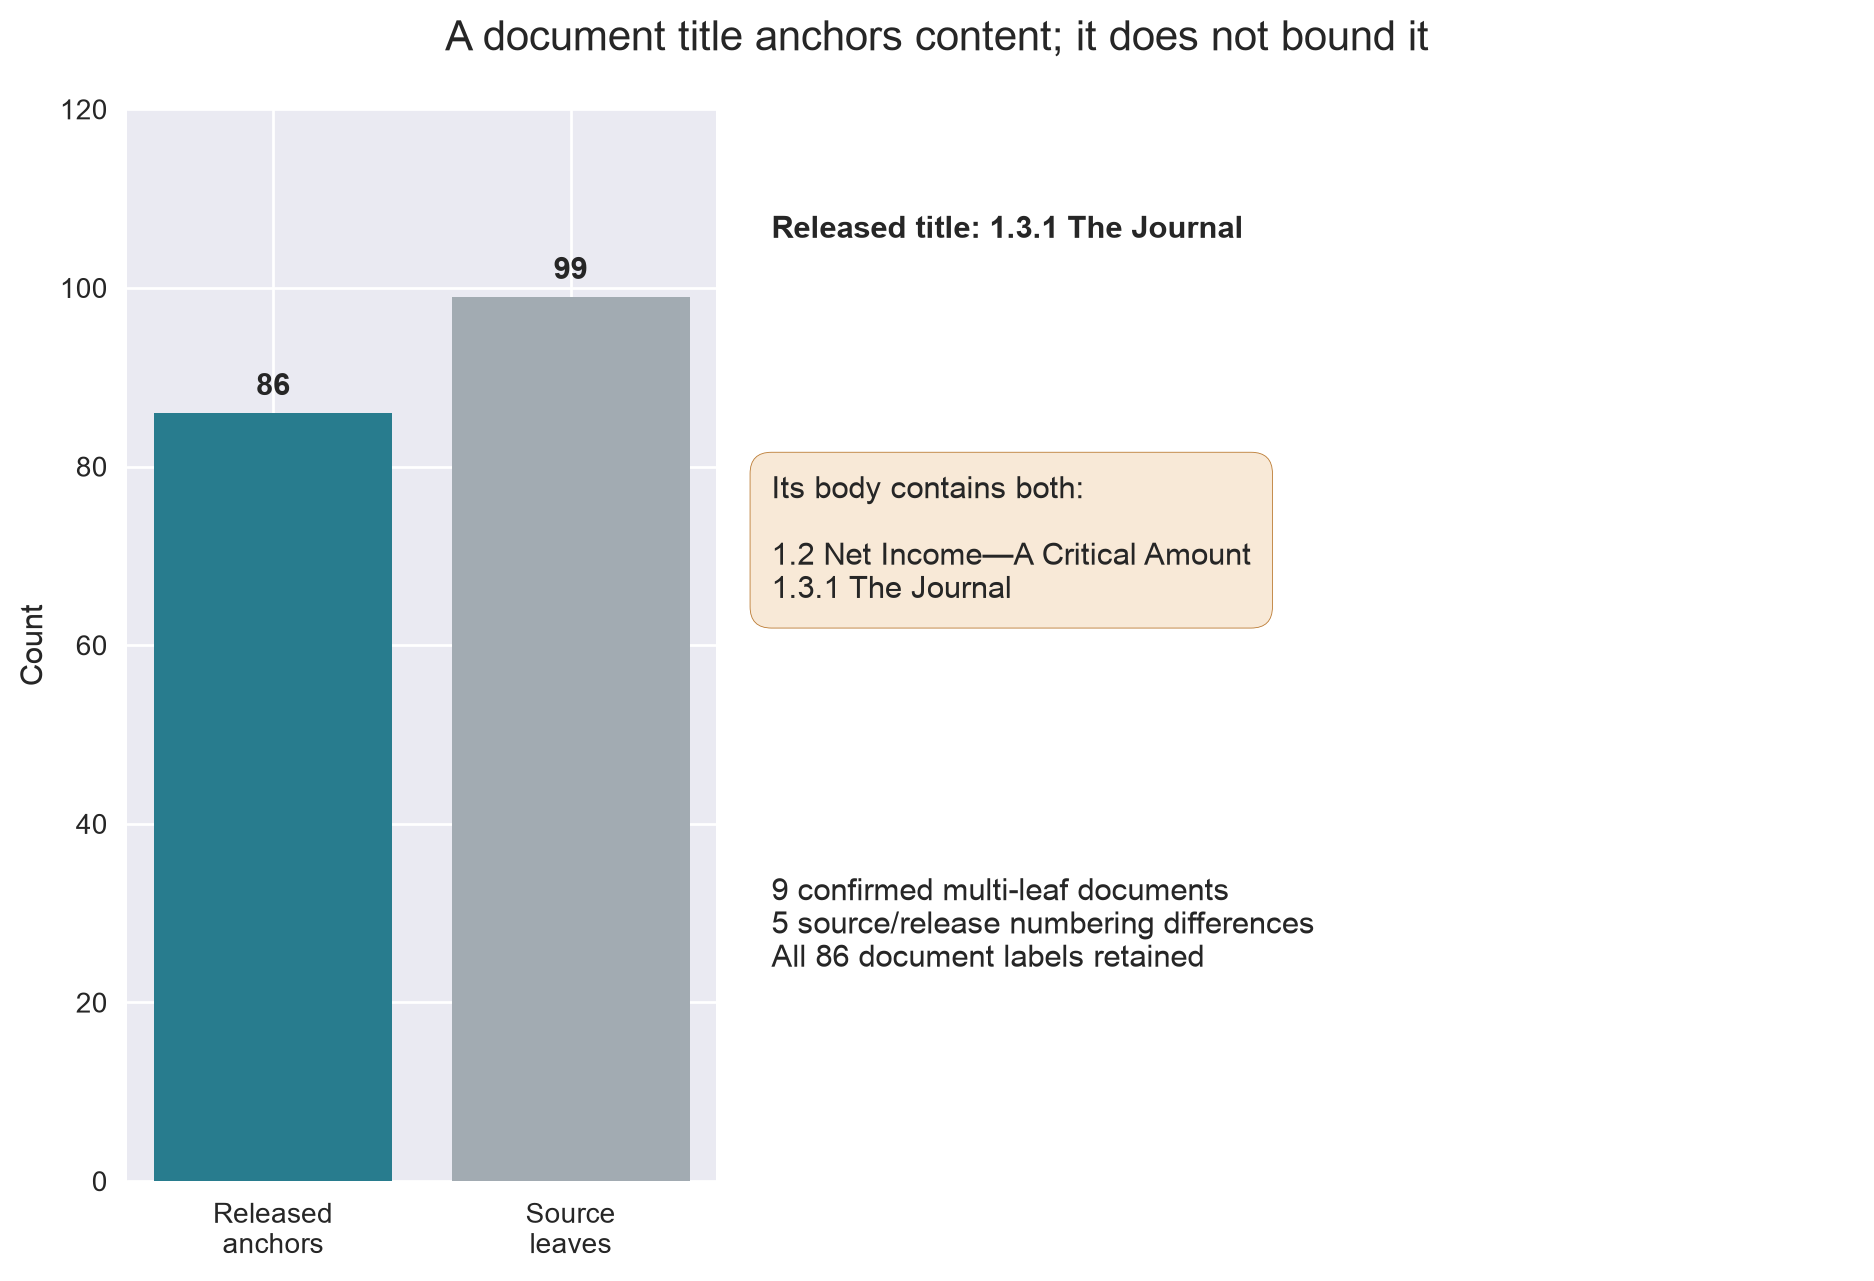

*Caption:* The original source-leaf assumption failed; v4 retains 86 released documents as verified title anchors.

The tree represents source-derived anchor paths, not a partition of the bodies. The nine positive boundary cases remain evidence.

In [11]:
if CFG.MODE == 'live':
    result = run_experiment()
elif CFG.MODE == 'report':
    result = load_experiment()
else:
    prepare_sources()
    prepare_model_cache()
    result = load_experiment()
print('Evidence run:', result['run'])
print('Boundary warnings retained:', result['audit']['confirmed_multi_leaf_documents'])
assets = export_publication(result)
show_visual(assets, 1)

All 86 candidates are retained. The original section-boundary failure remains visible. The numerical study must complete before its matched comparison is reported.

# Start by searching the text

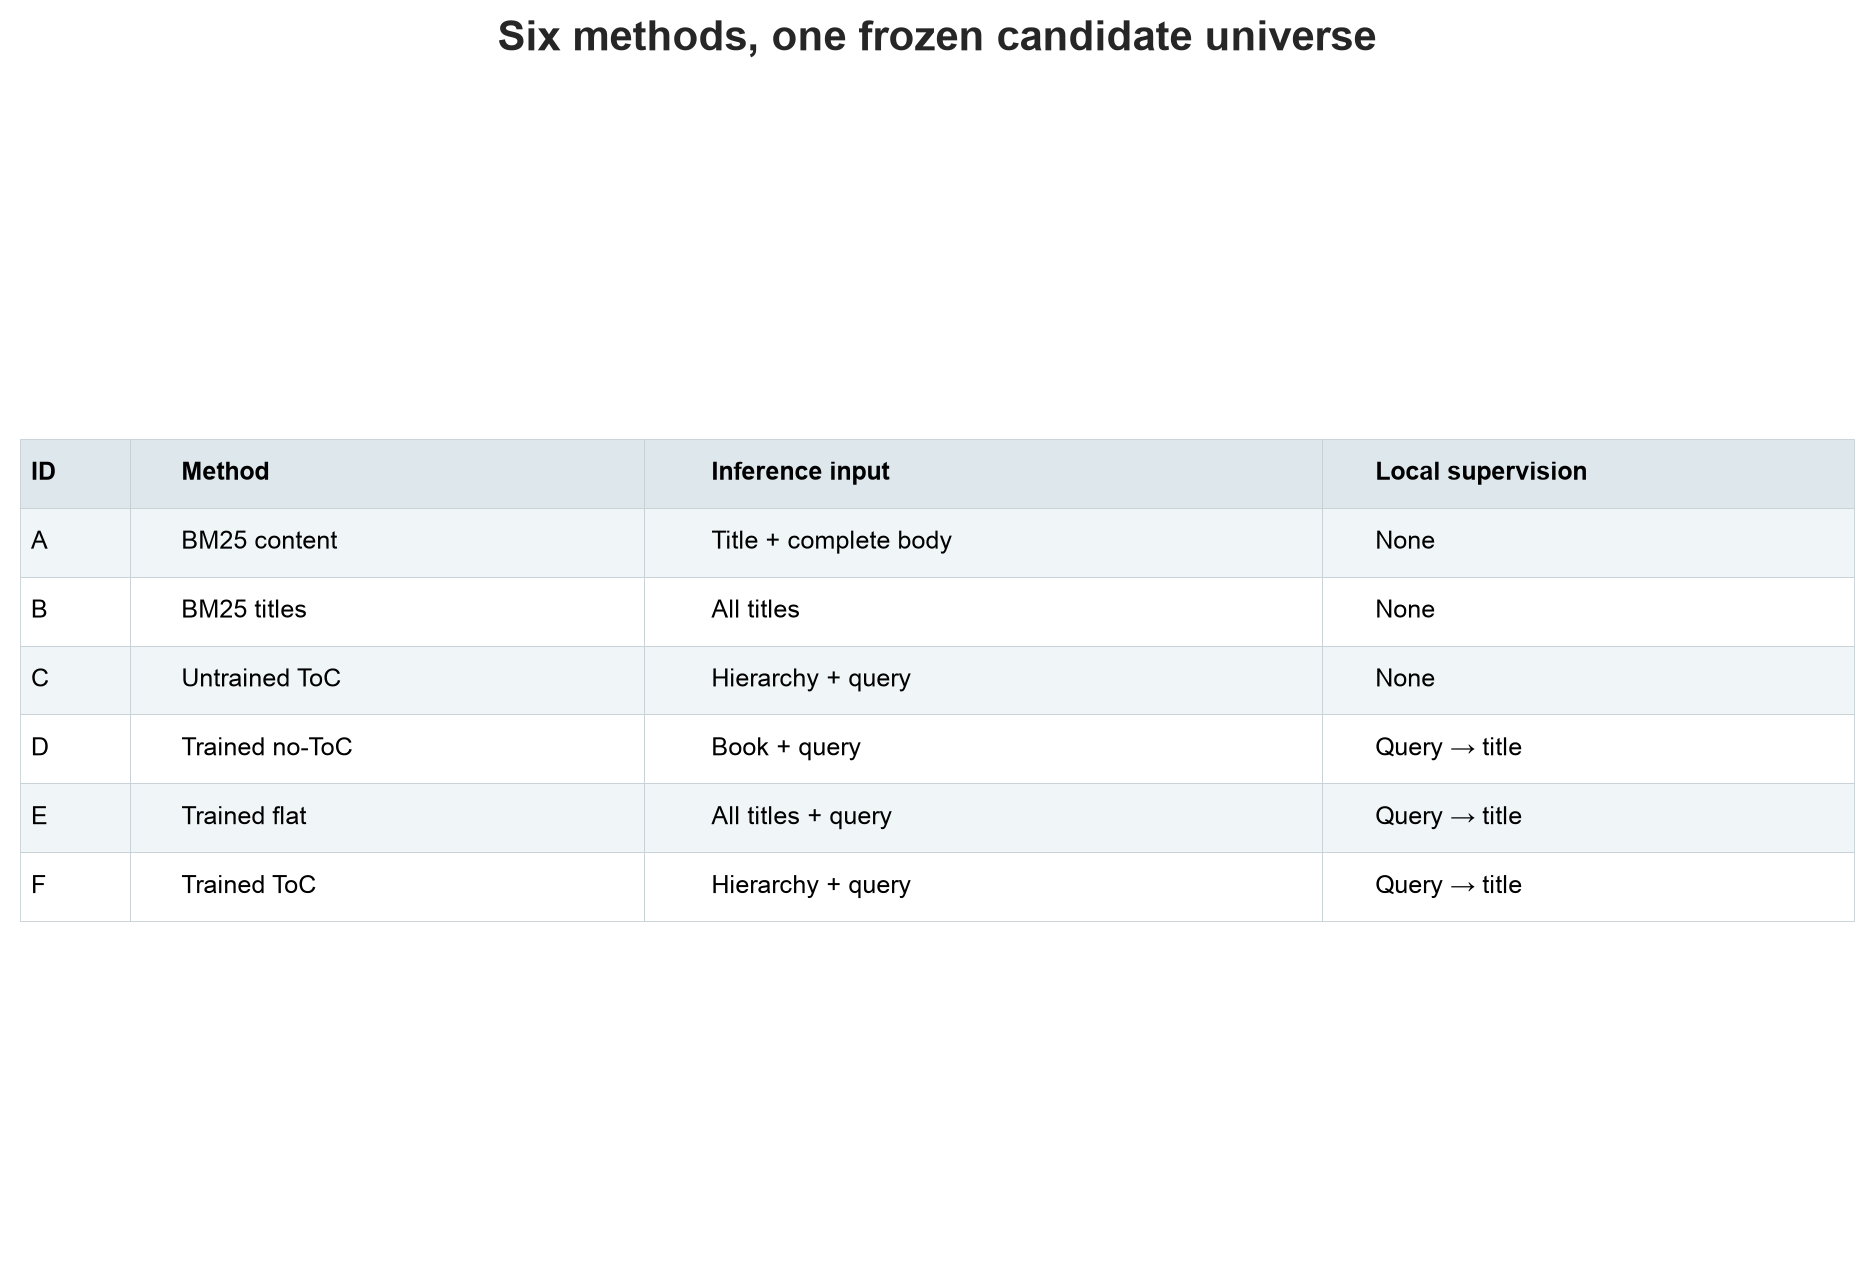

*Caption:* All methods retrieve the same unchanged 86 documents; C/D/E/F share a tokenizer and valid-label trie.

F–D is the primary contrast. F–E adds ancestor semantics and organization; it does not isolate topology.

In [12]:
show_visual(assets, 2)

A searches each unchanged complete released body; B searches titles. C/D/E/F share the exact candidate-title vocabulary. Every row uses the same frozen test membership, including annotation flags in the primary denominator.

# Learn to return a section title

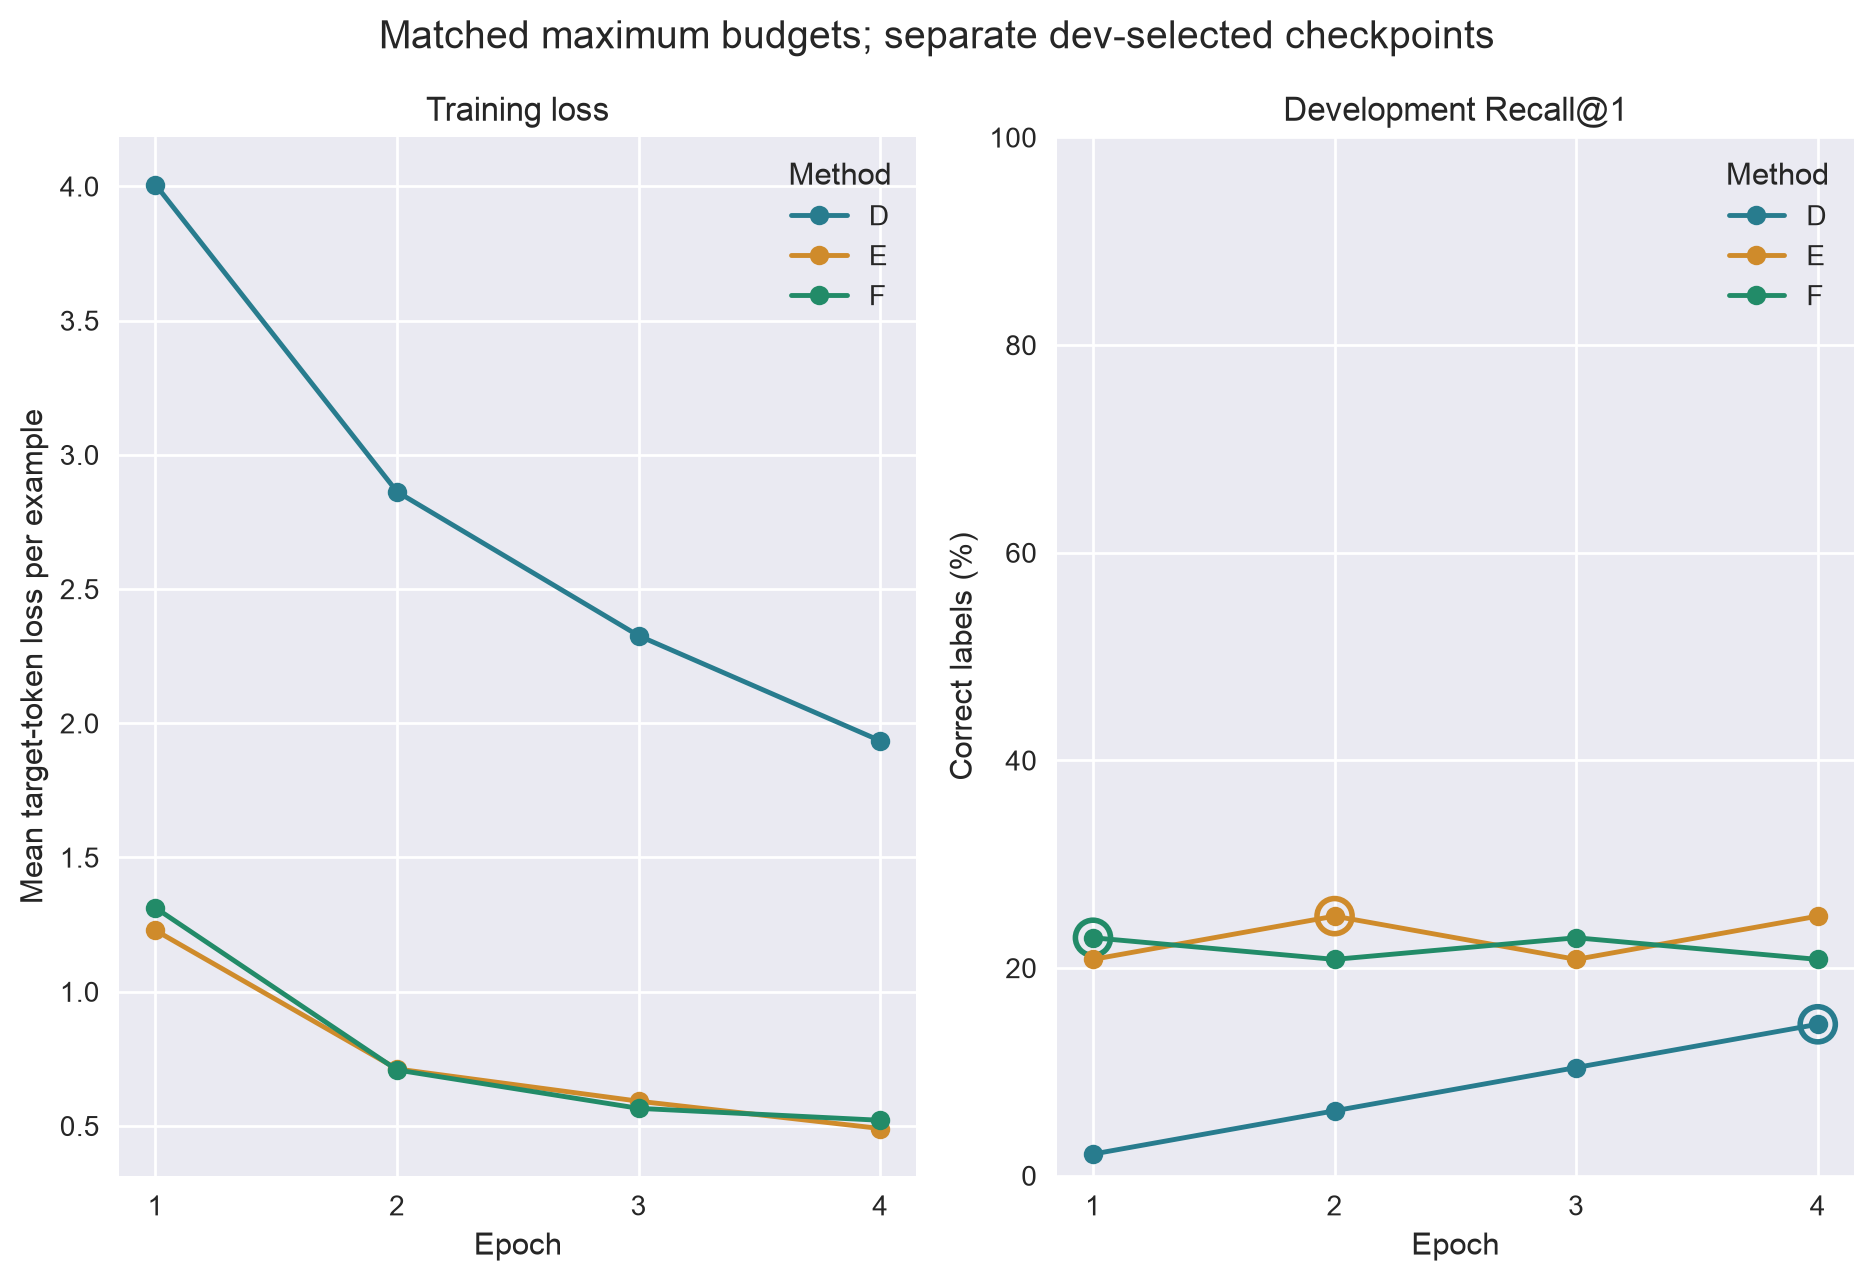

*Caption:* Training/dev curves for D/E/F. Rings indicate the earliest best development checkpoint within each arm.

Lower loss is an optimization diagnostic. It does not establish full convergence, seed stability or held-out benefit.

In [13]:
show_visual(assets, 3)

The generated section-style string is a released-document label. Selected epochs can differ despite the same initial weights and maximum update budget.

# Give the model the table of contents

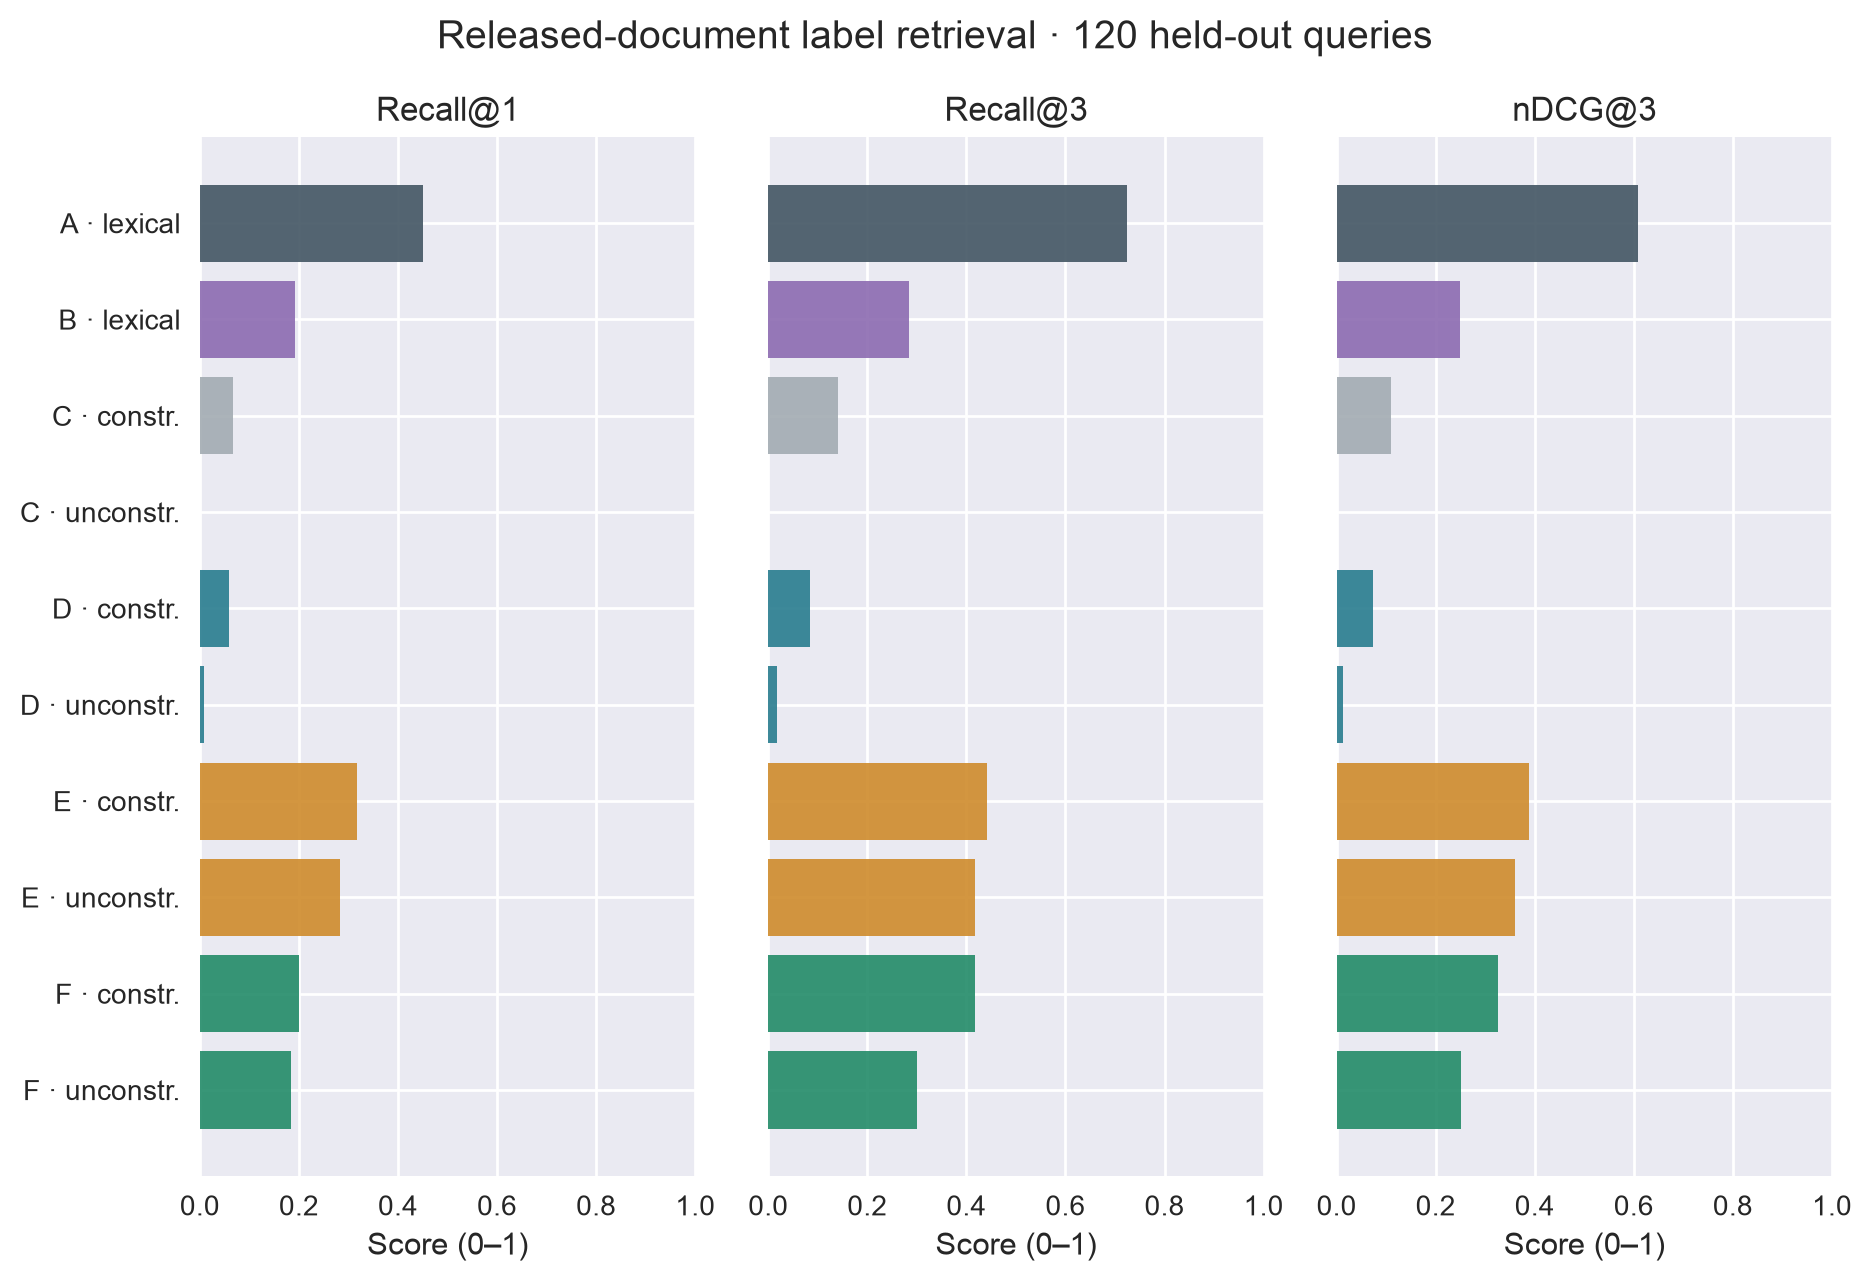

*Caption:* Held-out label metrics for all methods and both neural decode modes, with identical query membership.

Invalid outputs keep their rank and receive zero relevance; constrained legality alone is not accuracy.

In [14]:
show_visual(assets, 4)

D sees the book and query; E adds every target title; F adds verified ancestor headings and organization. F–E measures that combined information and formatting change, not topology alone.

# A valid title can still be wrong

Constrained validity is a software invariant. Unconstrained invalid labels and valid-but-wrong labels are distinct. A retrieved body can span several source leaves under the approved anchor interpretation.

# Count the gains and the losses

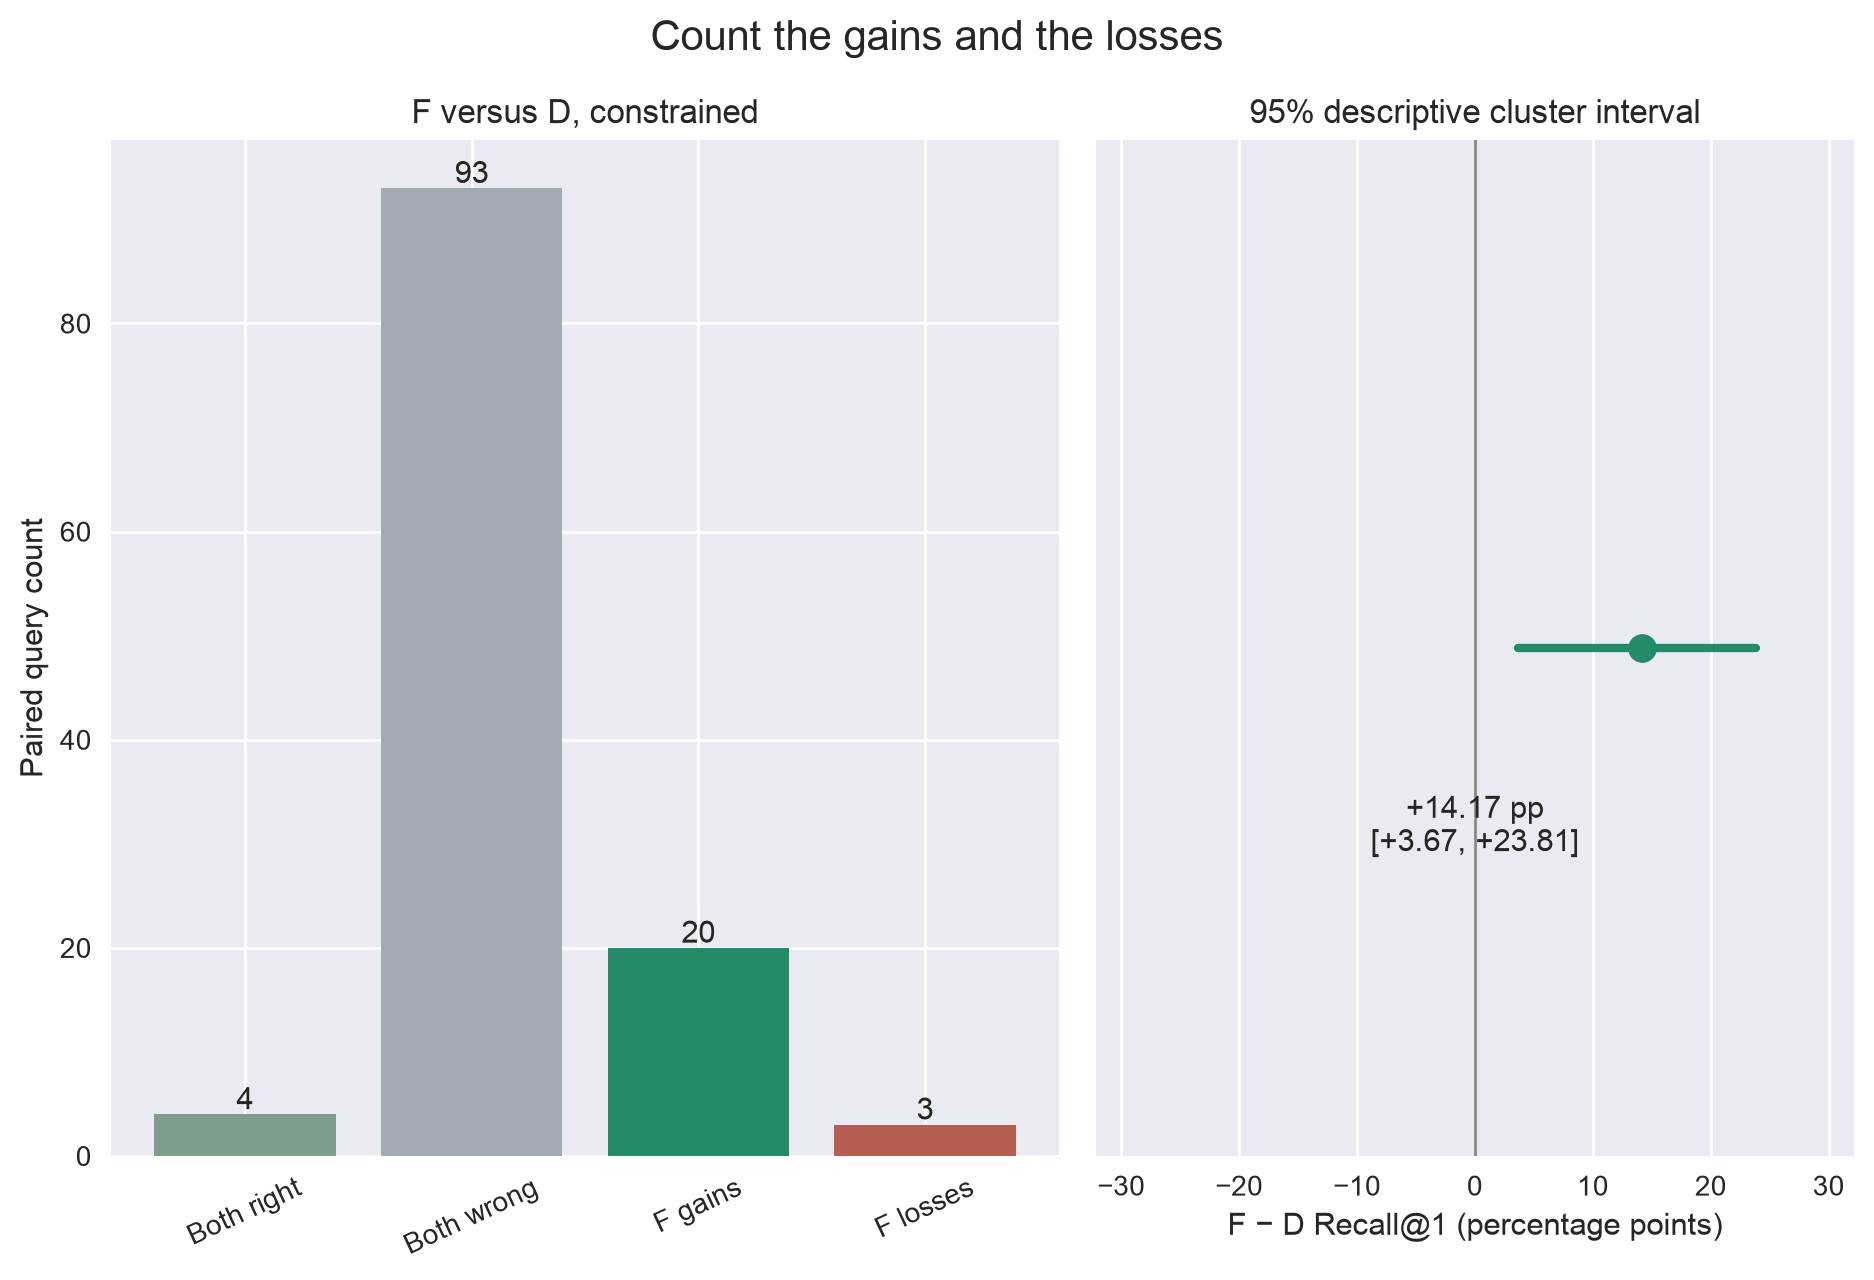

*Caption:* Primary paired constrained F–D Recall@1 difference with a 95% percentile document-cluster bootstrap interval.

The interval is conditional on this book, sample and seed. It is not a cross-book or training-seed uncertainty estimate.

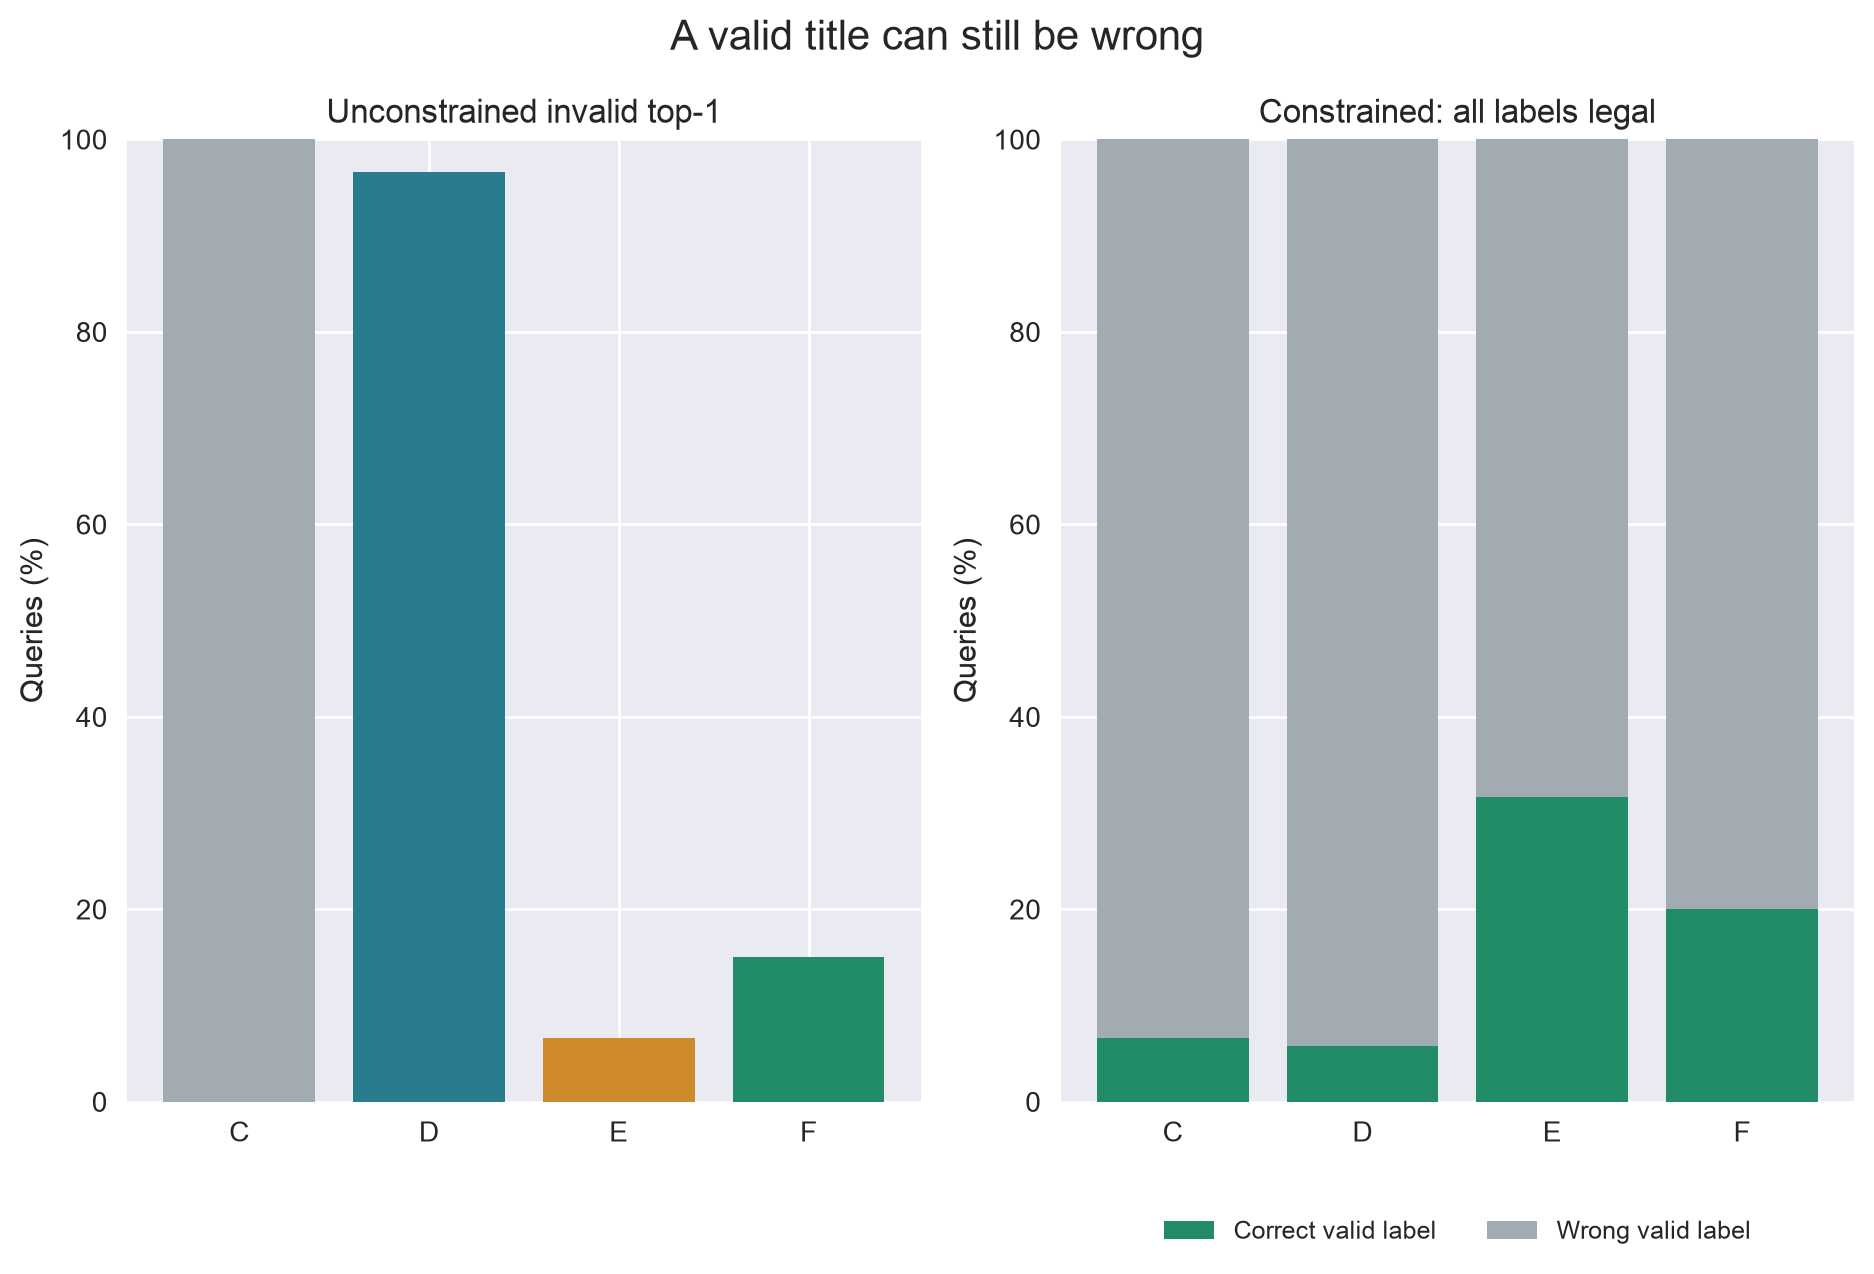

*Caption:* Unconstrained invalid-label rates and constrained correct/wrong-valid outcomes on the same queries.

The trie enforces constrained validity; any reduction in unconstrained invalidity is a separate learned-adherence observation.

In [15]:
show_visual(assets, 5)
show_visual(assets, 6)

The percentage-point contrast is paired on identical questions. The interval clusters by gold document label; it does not cover books, independent paragraphs or training seeds.

# What happens to rarely trained sections

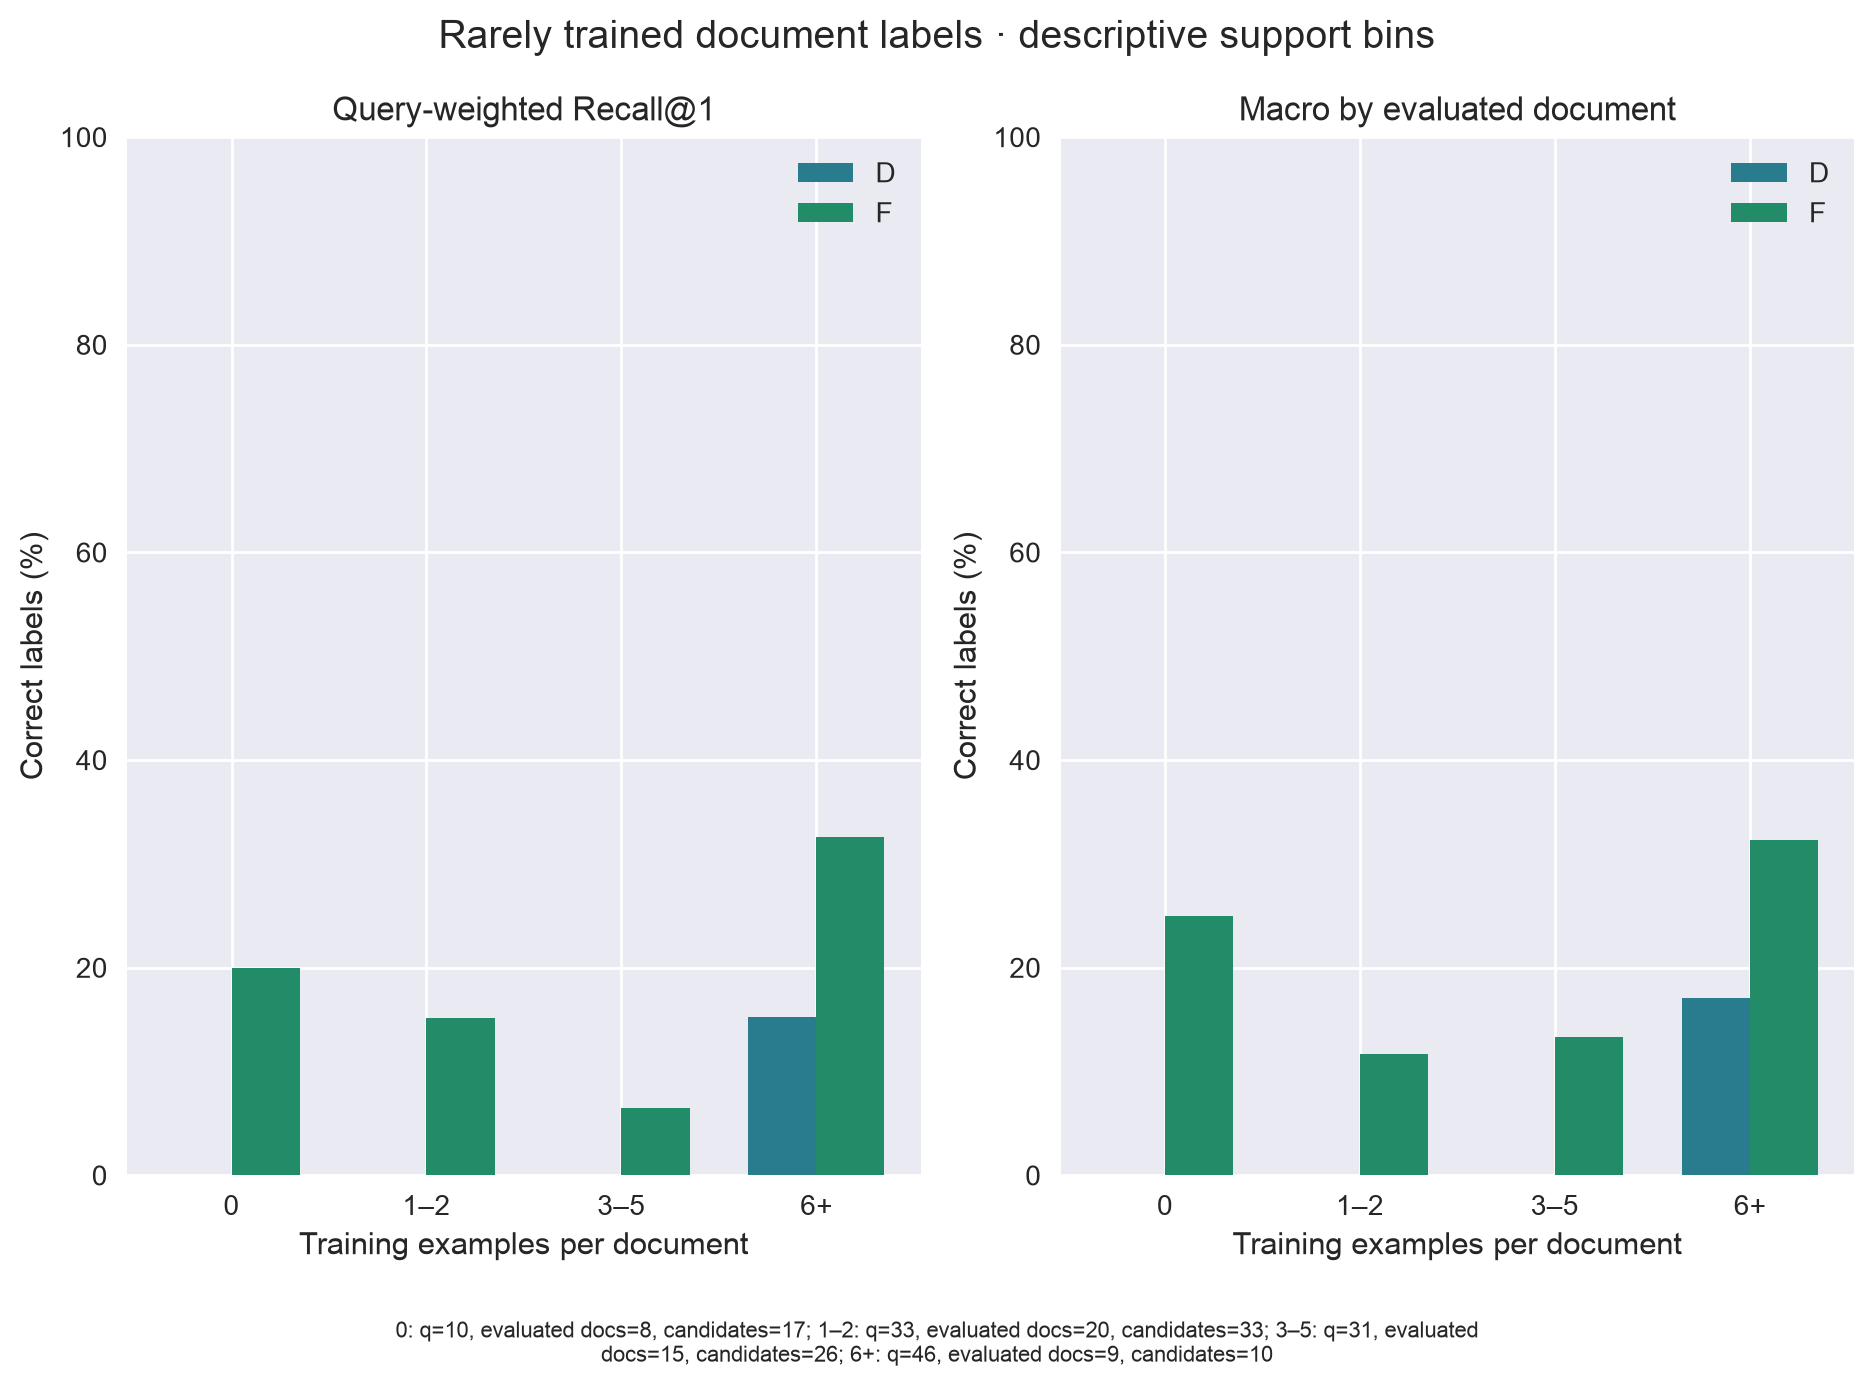

*Caption:* Training-support bins for constrained D/F, including query and document denominators; empty bins are not zero accuracy.

Support is observational. Zero-training labels still occur in the complete catalogue and are not unseen-book targets.

In [16]:
show_visual(assets, 7)

Support bins use the actual training membership. Candidate counts, evaluated-document counts and query counts have different meanings. Zero-support documents still appear in the supplied catalogue.

# Cost, failures and what remains uncertain

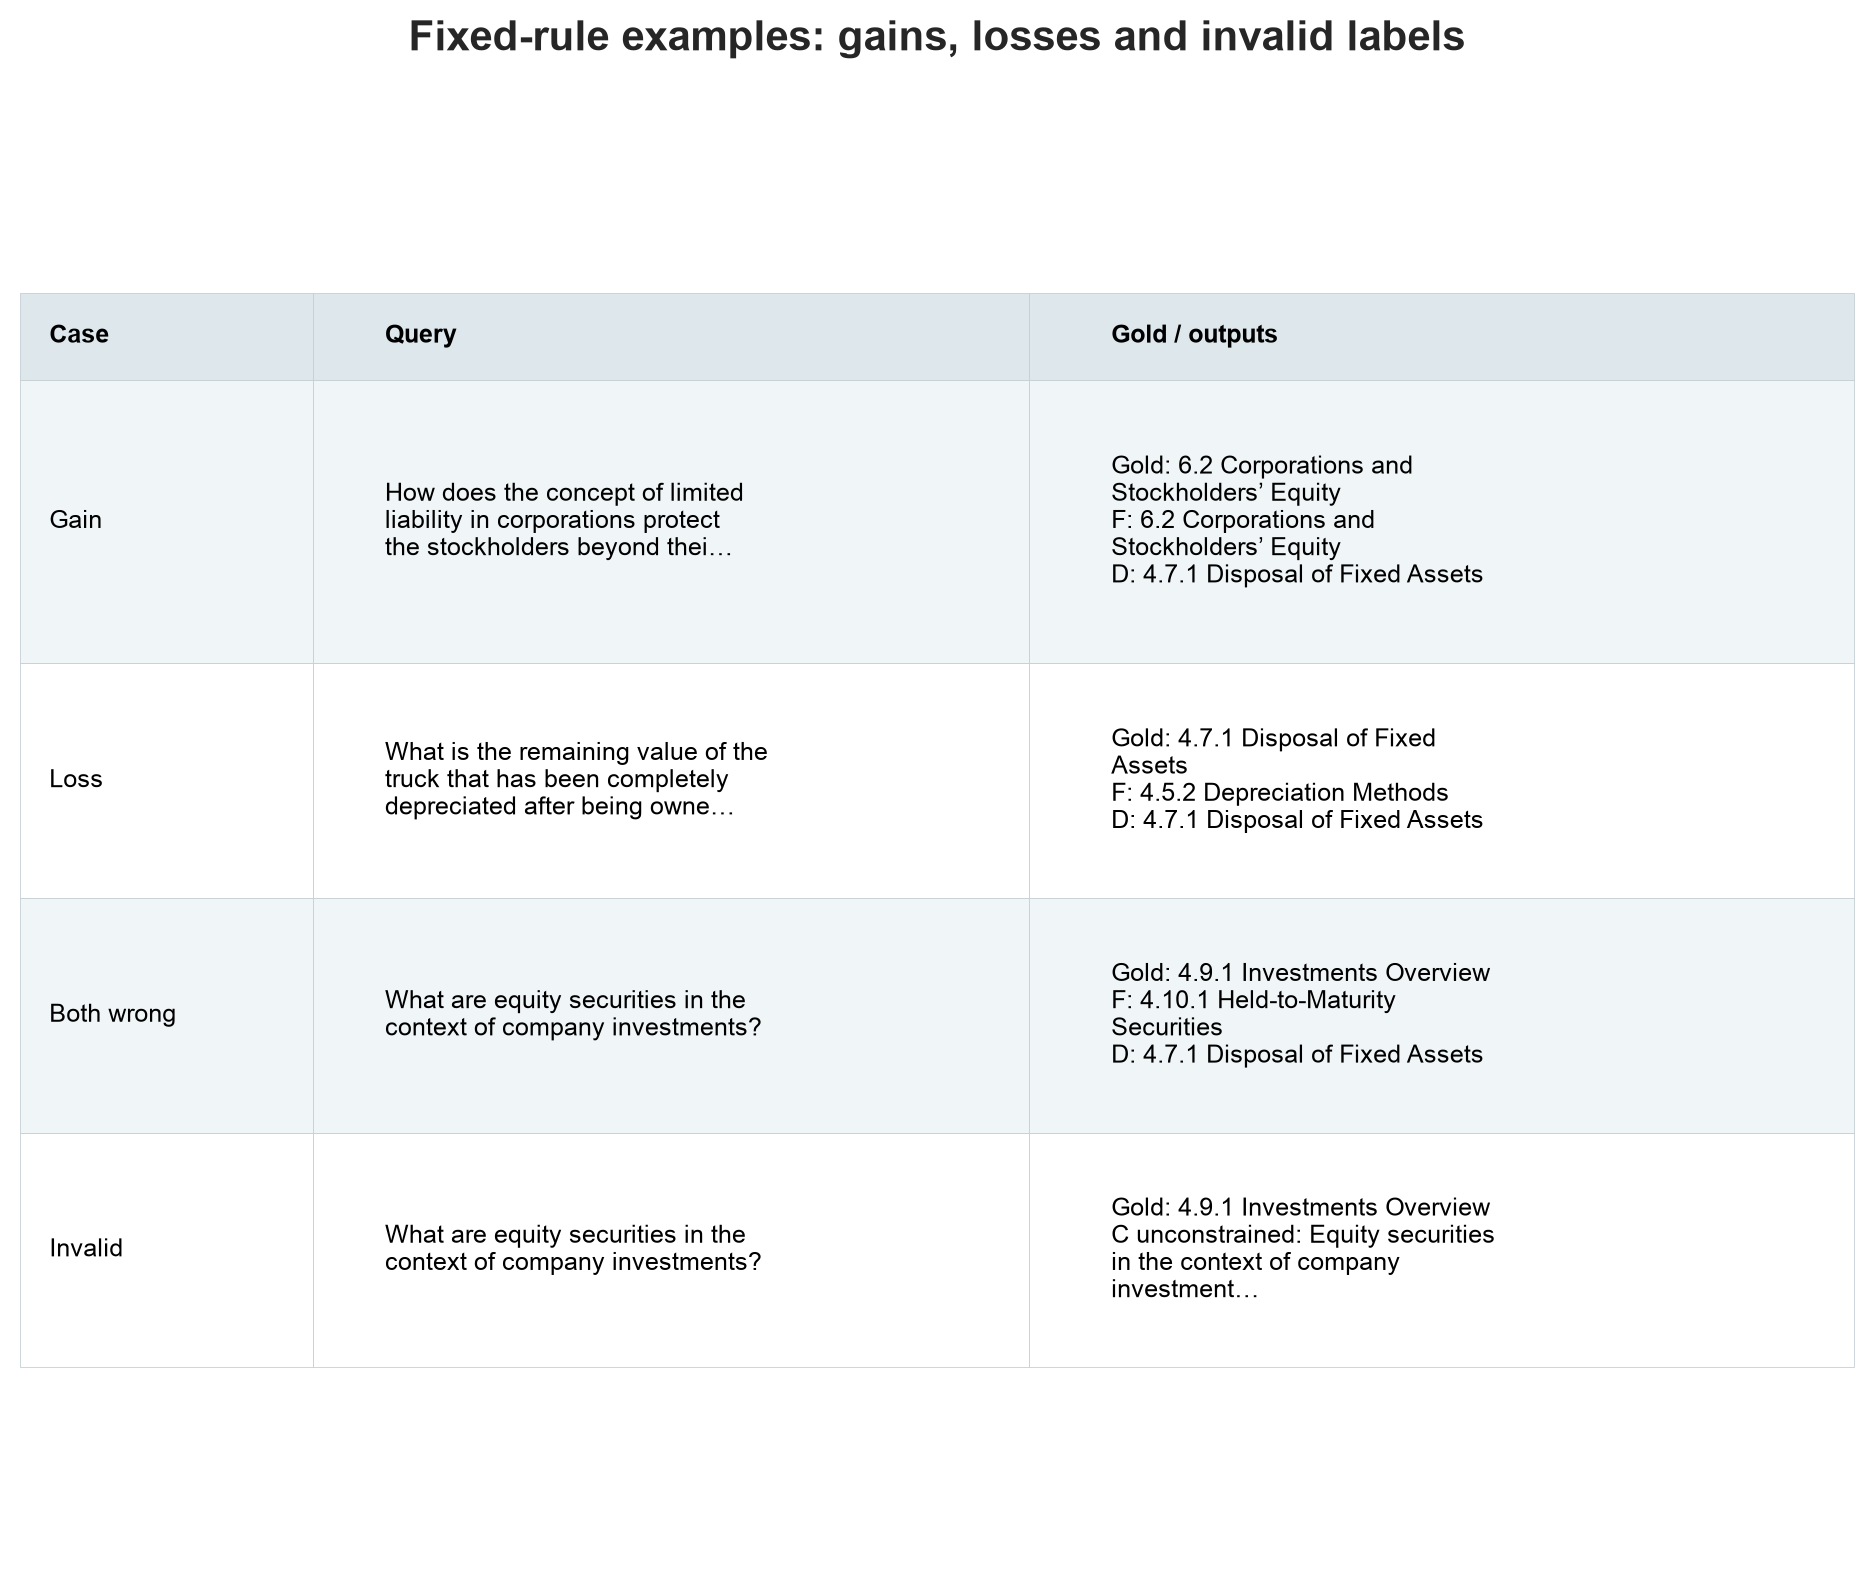

*Caption:* Lowest-qualified-ID gain, loss and both-wrong cases; lowest-ID unconstrained invalid output, with method-ID tie breaking.

Display excerpts are shortened for layout only. Complete questions, target strings, outputs and IDs are in the JSON/CSV sidecars.

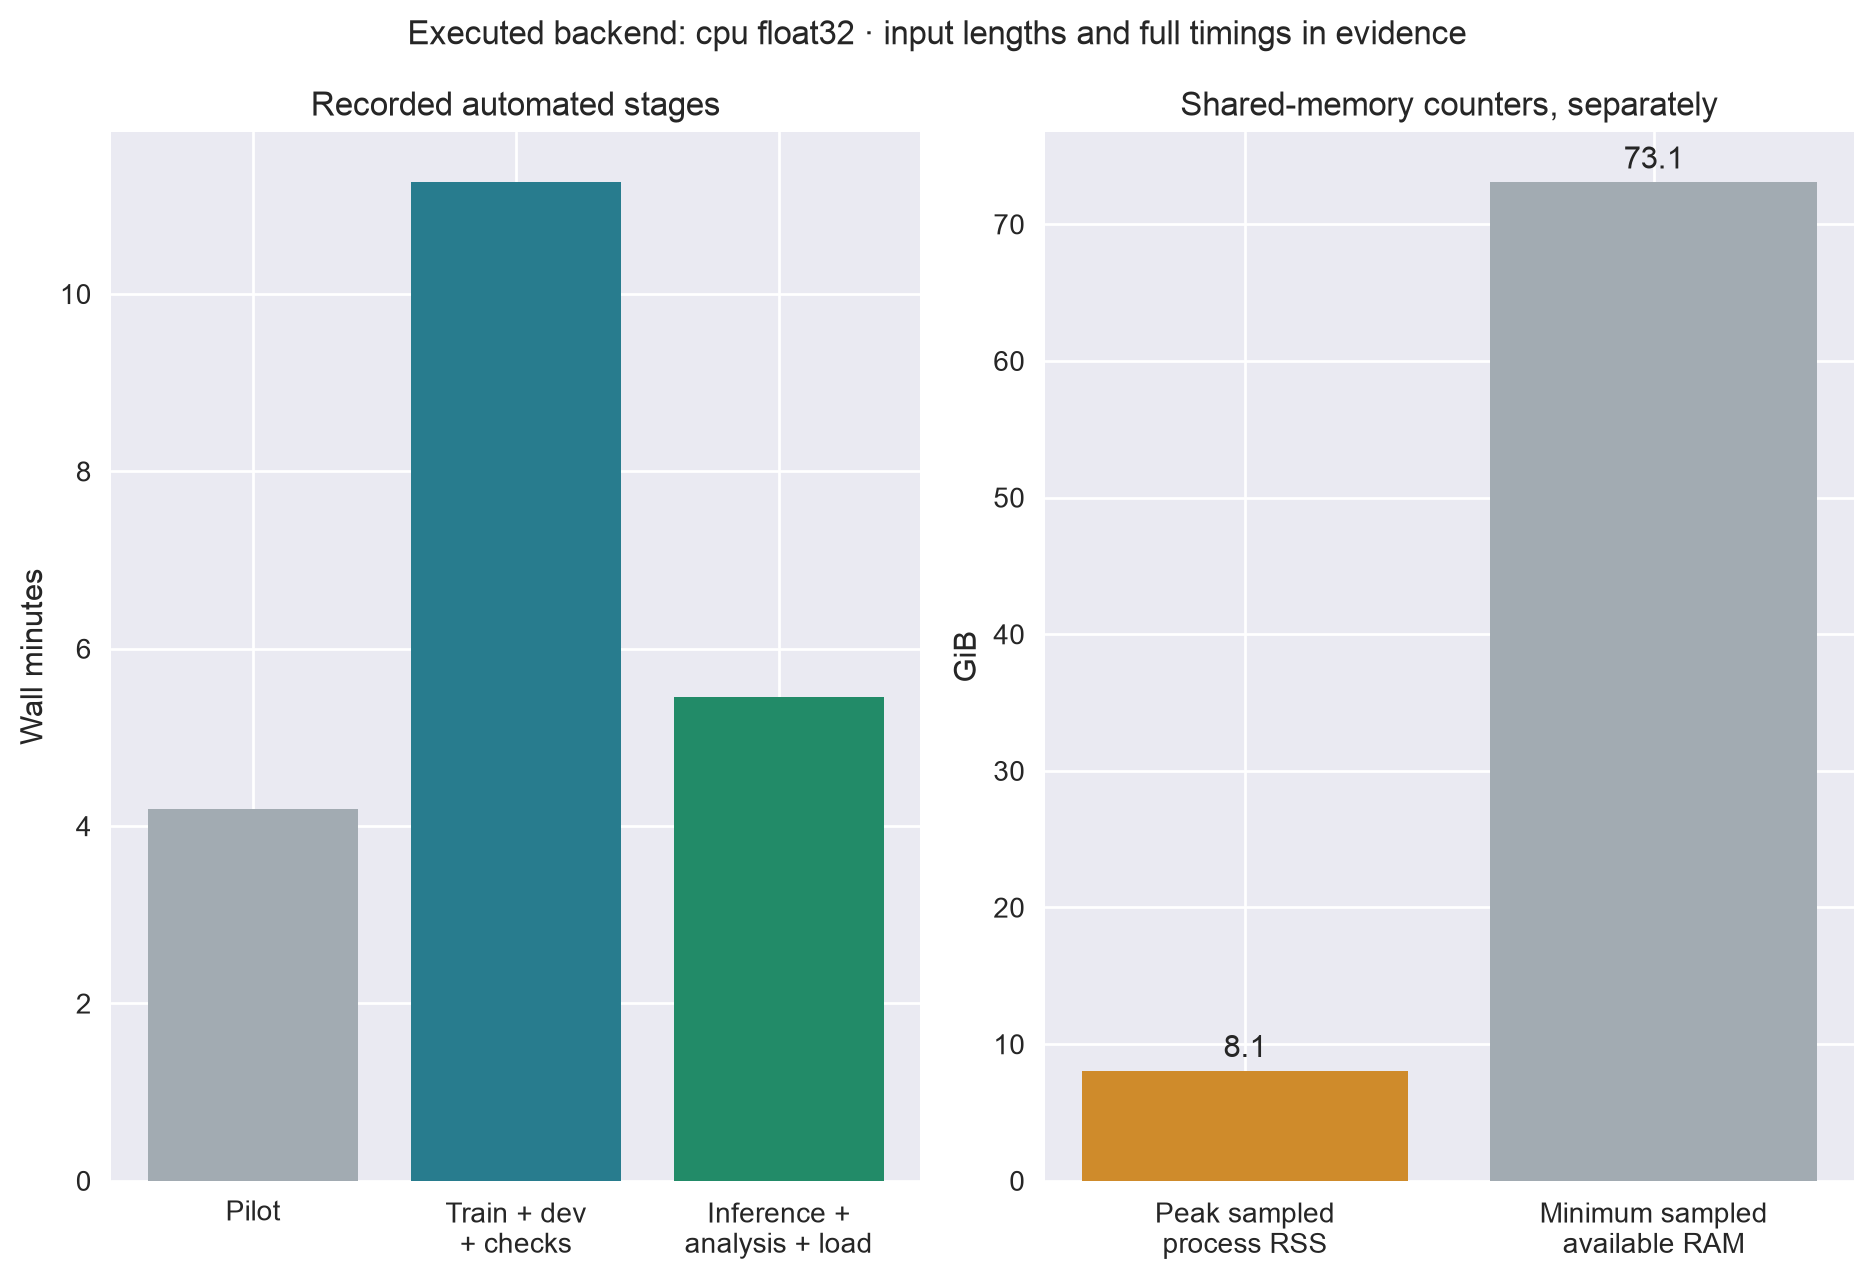

*Caption:* Recorded automated-stage times and sampled host-memory counters; model fitting and held-out inference are distinct costs.

Preparation/probes/authoring are additional and not fully metered here. Replay is not fresh inference speed. Shared counters are not additive VRAM pools.

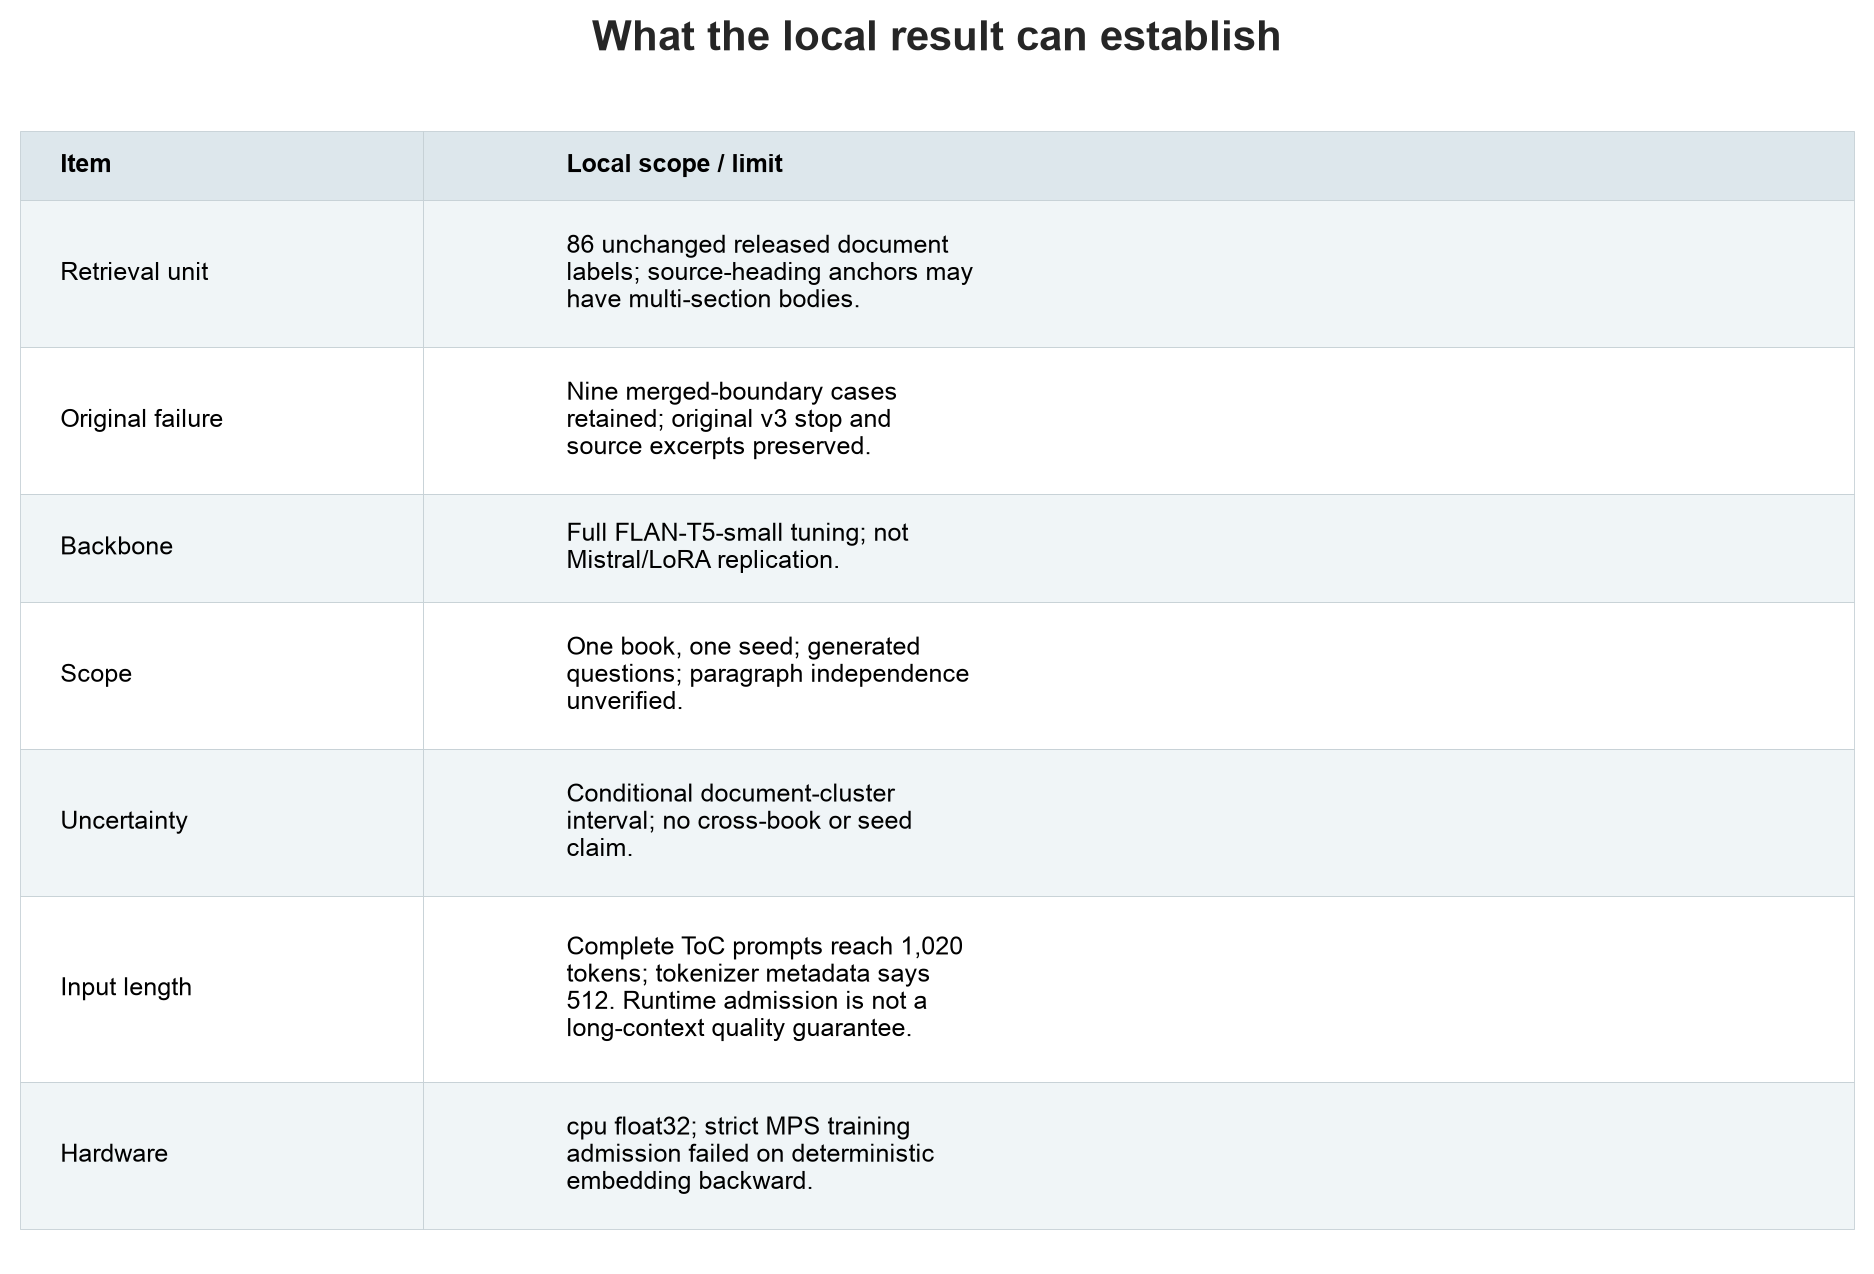

*Caption:* Paper/local differences, the original source-boundary failure and unresolved generalization/runtime limits.

Any positive result remains a local released-label finding. The decision changed the interpretation; it did not clean or repartition the bodies.

Historical v3 section failure preserved; v4 unit: unchanged released document with verified title anchor.


In [17]:
show_visual(assets, 8)
show_visual(assets, 9)
show_visual(assets, 10)
write_current_report(result, assets)
print('Historical v3 section failure preserved; v4 unit: unchanged released document with verified title anchor.')

Training/development cost is separate from inference latency. Batch throughput is not singleton latency. Preparation, development probes and authoring add to project cost; replay measures no new inference speed.

# Closing time

In [18]:
display(Markdown(result_reading(result)))

**Observed outcome:** constrained hierarchy F=20.00%, no-ToC D=5.83%, flat catalogue E=31.67% and BM25 content A=45.00% Recall@1. F–D=+14.17 pp; descriptive F–E=-11.67 pp. A gain over no-ToC alone does not establish an added benefit from hierarchy over a catalogue. These are released-document label scores on the frozen local sample, not exact source-section or downstream-answer quality.

Interpret the captured result as a one-book, one-seed, small-model adaptation. The record retains the source failure that motivated the anchor contract. Numerical completion does not establish exact content partitioning, unseen-book generalization or downstream factual correctness.

Attribution: SearchTome, meghanadh/SearchTome, CC BY-SA 4.0; Christine Jonick, *Principles of Financial Accounting*, University of North Georgia Press (2017), attributing the University System of Georgia. Retain source copyright exceptions. FLAN-T5-small model card: Apache-2.0.